# Flux post-processing chain: IRGA75 latent heat flux (2004-2017)

**notebook version**: `1` (29 Oct 2026). Adapted from the IRGA72 notebook `25_FPPC_IRGA72_LE_2016-2026.09`.

## ℹ️ About this notebook

Processes a latent heat flux with the [diive flux post-processing chain](https://diive.readthedocs.io/en/latest/flux_postprocessing.html): outliers (L3.2),
gap-filling (L4.1) and the conversion to evapotranspiration (ET). As in FLUXNET2015 and ONEFlux
(Pastorello et al. 2020), LE gets no storage term (L3.1) and no USTAR filter (L3.3); both levels
run, because the chain needs them. The site, flux, period and all settings are in *Settings*;
*Data sources* links the site documentation, which holds the decisions and periods specific to the
site.

`TEST_RUN = True` runs one year (`TEST_YEAR`) and writes its own output file.

***

## 📇 Data sources

The input `30_FLUX_POST-PROCESSING_CHAIN/IRGA75/01_FPPC_IRGA75_INPUT_OPCO_2004-2017_2019.parquet` in
the external data folder holds the Level-1 fluxes of the open-path IRGA75 (LI-7500) runs and the
meteo data of the site. The opco correction of that file applies to the CO2 flux only; `LE` is
used as EddyPro calculated it.

Site documentation (CH-LAE): the processing levels, settings, periods removed by hand and known
limitations are on the [CH-LAE flux product site](https://holukas.github.io/dataset_ch-lae_flux_product/FPC.html), Levels 3.1 to 4.2.

## ⚙️ Settings

In [1]:
# --- Source ------------------------------------------------------------------------------------
DATADIR = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
           r"\workflow")
SOURCEFILE = rf"{DATADIR}\30_FLUX_POST-PROCESSING_CHAIN\IRGA75\01_FPPC_IRGA75_INPUT_OPCO_2004-2017_2019.parquet"

# --- Testing -----------------------------------------------------------------------------------
# TEST_RUN = True processes only TEST_YEAR, a quick check of the whole notebook. A test run writes
# its own output file, so it never overwrites the result of a full run.
TEST_RUN = False
TEST_YEAR = 2004
# Years to process: the full calendar years with IRGA75 fluxes, as in the IRGA75 CO2 notebook 05.
# The input also holds 2018, without any IRGA75 flux, and 2019 with only the stand-in run of
# 17 January to 20 March; neither is gap-filled here.
YEARS = [TEST_YEAR] if TEST_RUN else list(range(2004, 2018))

# --- Output ------------------------------------------------------------------------------------
OUTNAME = "25_FPPC_IRGA75_LE_2004-2017"  # same name as this notebook
if TEST_RUN:
    OUTNAME += f"_TEST_{TEST_YEAR}"
OUTPATH = rf"{DATADIR}\30_FLUX_POST-PROCESSING_CHAIN\IRGA75"

# --- Site and flux -----------------------------------------------------------------------------
FLUXCOL = 'LE'  # latent heat flux of the open-path LI-7500 (W m-2), without storage term
SITE_LAT = 47.478333  # CH-LAE
SITE_LON = 8.364389
UTC_OFFSET = 1  # timestamps are UTC+01:00 all year
NIGHTTIME_THRESHOLD = 20  # W m-2 potential radiation below this = nighttime
DAYTIME_ACCEPT_QCF_BELOW = 2  # keep QCF 0 and 1
NIGHTTIME_ACCEPT_QCF_BELOW = 2

# --- Level 2 -----------------------------------------------------------------------------------
# The VM97 test reads H2O_VM97_TEST, the SSITC and SCF tests LE_SSITC_TEST and LE_SCF.
LEVEL2_SETTINGS = {
    # AGC of the LI-7500 (%): 50 is a very good signal, above 90 a bad one, as in the CO2 notebook 05.
    'signal_strength': {'apply': True,
                        'signal_strength_col': 'CUSTOM_AGC_IRGA75_MEAN',
                        'method': 'discard outside',
                        'threshold': (40, 90)},
    'raw_data_screening_vm97': {'apply': True,
                                'spikes': True, 'amplitude': False, 'dropout': True,
                                'abslim': False, 'skewkurt_hf': False, 'skewkurt_sf': False,
                                'discont_hf': False, 'discont_sf': False},
    'ssitc': {'apply': True, 'setflag_timeperiod': None},
    'gas_completeness': {'apply': False},
    'spectral_correction_factor': {'apply': True},
    'angle_of_attack': {'apply': False, 'application_dates': []},
    'steadiness_of_horizontal_wind': {'apply': False},
}
LEVEL2_INPUTS = ['LE_SSITC_TEST', 'LE_SCF', 'H2O_VM97_TEST']

# --- Level 3.2 ---------------------------------------------------------------------------------
# Periods removed by hand (date ranges, whole days, both ends included). The reasons are in the
# site documentation (Level 3.2).
REMOVE_DATES = [
    ['2004-12-01', '2004-12-15'],  # fog and rime, as for FC: nighttime LE down to -50, daytime LE negative
    ['2013-11-16', '2013-11-23'],  # fog and rime, as in December 2004
    ['2014-11-09', '2014-11-12'],  # fog and rime, as in December 2004
    ['2014-11-24', '2014-12-07'],  # fog and rime, as in December 2004
]
# Absolute limits (W m-2), as in the 2016-2024 LE notebook.
ABSLIM = (-100, 1000)

# --- Level 3.3 ---------------------------------------------------------------------------------
# No USTAR filter for LE. The chain needs Level 3.3 before gap-filling, so it runs with a single
# scenario at a threshold of 0, which removes no record.
USTAR_THRESHOLDS = [0]
USTAR_SCENARIOS = ['CUT_NONE']
USTAR_SCENARIO = USTAR_SCENARIOS[0]

# --- Level 4.1: meteo drivers ------------------------------------------------------------------
TA_F = 'TA_T1_47_1_HOMOGENIZED_gfXG'    # degC, complete; also used for ET
SW_IN_F = 'SW_IN_T1_47_1_gfXG'          # W m-2, complete
VPD_F = 'VPD_T1_47_1_HOMOGENIZED'       # kPa, complete
TA_FLAG = 'FLAG_TA_T1_47_1_ISFILLED'    # 0 = measured at 47 m
SW_IN_FLAG = 'FLAG_SW_IN_T1_47_1_ISFILLED'
VPD_FLAG = 'FLAG_VPD_T1_47_1_ISFILLED'
FEATURES = [TA_F, SW_IN_F, VPD_F]

FLUX_UNITS = 'W m-2'

# 30-min LE in W m-2 -> MJ m-2 per half-hour, for sums and cumulatives.
W_TO_MJ = 1800 / 1e6

# MDS gap-filling, next to XGBoost, to compare the two methods. mode='diive' fills every gap,
# also long ones; the QC flags keep model-filled driver values out of the similar samples.
RUN_MDS = True
MDS_SETTINGS = dict(mode='diive', fill_long_gaps=True)

# XGBoost hyperparameters, at the production values suggested by the diive notebook.
XGB_SETTINGS = dict(n_estimators=1000, max_depth=6, learning_rate=0.05,
                    random_state=42, n_jobs=-1, shap_max_rows=5000)

# --- Evapotranspiration ------------------------------------------------------------------------
# et_from_le returns mm h-1; times this factor gives mm per half-hour.
HOURS_PER_RECORD = 0.5

In [2]:
from datetime import datetime
import importlib.metadata
import warnings

import diive as dv
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from diive.core.ml.feature_engineer import FeatureEngineer
from diive.core.plotting.styles import chainplots as cp
from diive.core.times.times import doy_cumulatives_per_year, doy_mean_cumulative
from diive.flux.postprocessingchain import (
    init_flux_data,
    make_level32_detector,
    run_level2,
    run_level31,
    run_level32,
    run_level33_constant_ustar,
    run_level41_mds,
    run_level41_xgb,
    # Reporting over the finished chain
    plot_feature_ranks_per_year,
    plot_tree_selection,
    plot_gapfilling_comparison,
    plot_gapfilling_input,
    plot_quality_heatmaps,
    plot_quality_timeseries,
    report_annual_sums,
    report_gapfilling_comparison,
    report_gapfilling_feature_importances,
    report_gapfilling_input,
    report_gapfilling_model_scores,
    report_gapfilling_poolyears,
    report_gapfilling_variables,
    report_gaps,
    report_model_overview,
    report_traintest_model_scores,
    report_tree_selection,
)
from diive.variables.thermodynamic import et_from_le

# The notebook's inline backend renders each figure itself; diive's own fig.show() call can only
# warn that it cannot open a window.
warnings.filterwarnings('ignore', message='FigureCanvasAgg is non-interactive')

# Start time is kept so the last cell can report the total runtime of the notebook.
NOTEBOOK_START = datetime.now()
print(f"Last run: {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"diive version: v{importlib.metadata.version('diive')}")

Last run: 2026-10-30 18:22:19
diive version: v0.93.0


## 📂 Load data

`init_flux_data` adds `SW_IN_POT`, `DAYTIME` and `NIGHTTIME` itself and stops if they already exist,
so they are removed from the input first.

In [3]:
df = dv.load_parquet(filepath=SOURCEFILE)
df = df.drop(columns=[c for c in ('SW_IN_POT', 'DAYTIME', 'NIGHTTIME') if c in df.columns])
df = df.loc[df.index.year.isin(YEARS)].copy()
assert sorted(set(df.index.year)) == sorted(YEARS), f"the input lacks some of the years {YEARS}"
assert (df.index[0], df.index[-1]) == (pd.Timestamp(f'{min(YEARS)}-01-01 00:15'),
                                       pd.Timestamp(f'{max(YEARS)}-12-31 23:45')), \
    f"the selected years run from {df.index[0]} to {df.index[-1]}, not over whole calendar years"

for _c in [FLUXCOL, TA_F, SW_IN_F, VPD_F, TA_FLAG, SW_IN_FLAG, VPD_FLAG, *LEVEL2_INPUTS,
           LEVEL2_SETTINGS['signal_strength']['signal_strength_col']]:
    assert _c in df.columns, f"{_c} is not in {SOURCEFILE}"
for _c in FEATURES:
    assert df[_c].notna().all(), f"driver {_c} has gaps"
print(f"{len(df):,} records x {df.shape[1]} columns, {df.index[0]} -> {df.index[-1]}")
print(f"{FLUXCOL}: {df[FLUXCOL].notna().sum():,} records")

> Loaded .parquet file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\30_FLUX_POST-PROC
ESSING_CHAIN\IRGA75\01_FPPC_IRGA75_INPUT_OPCO_2004-2017_2019.parquet (5.006 seconds).

245,472 records x 348 columns, 2004-01-01 00:15:00 -> 2017-12-31 23:45:00
LE: 200,208 records


## Step 1: set up the data

Calculates the potential radiation, marks day and night, and stores the site coordinates that later
steps use. `*_ACCEPT_QCF_BELOW = 2` keeps records with quality flag 0 (all tests passed) and 1
(minor warnings).

In [4]:
data = init_flux_data(
    df=df,
    fluxcol=FLUXCOL,
    site_lat=SITE_LAT,
    site_lon=SITE_LON,
    utc_offset=UTC_OFFSET,
    nighttime_threshold=NIGHTTIME_THRESHOLD,
    daytime_accept_qcf_below=DAYTIME_ACCEPT_QCF_BELOW,
    nighttime_accept_qcf_below=NIGHTTIME_ACCEPT_QCF_BELOW,
)
print(data)

──────────────────────────────────── Initializing flux data: LE ────────────────────────────────────

> Detected base variable H2O for LE. (H2O was used to calculate LE.)

> Potential radiation calculated (SW_IN_POT)

> Day/night flags: DAYTIME, NIGHTTIME

FluxLevelData(
  flux        = 'LE'
  levels run  = []
  fpc_df      = 245472 rows x 5 cols
  columns     = [LE, USTAR, SW_IN_POT, DAYTIME, NIGHTTIME]
  filtered    = None (no level has run yet)
)


## Step 2: quality flags (Level 2)

The tests in `LEVEL2_SETTINGS`, e.g. steady state and developed turbulence (SSITC), the spectral
correction factor, the signal strength of the analyser and spikes and dropouts in the raw data
(Vickers and Mahrt 1997). The table shows how many records each test removes.

In [5]:
data = run_level2(data, **LEVEL2_SETTINGS)
print(f'After L2: {data.filteredseries.dropna().count():,} valid records')

───────────────────────────────── Level 2: Quality Flag Expansion ──────────────────────────────────

> SSITC TEST: Generated new flag variable FLAG_L2_LE_SSITC_TEST, values taken from output variable
LE_SSITC_TEST ...

> SPECTRAL CORRECTION FACTOR TEST: Generating new flag variable FLAG_L2_LE_SCF_TEST, newly 
calculated from output variable LE_SCF, with flag 0 (good values) where LE_SCF < 2, flag 1 (ok 
values) where LE_SCF >= 2 and < 4, flag 2 (bad values) where LE_SCF >= 4...

> SIGNAL STRENGTH TEST: Generating new flag variable FLAG_L2_LE_SIGNAL_STRENGTH_TEST, newly 
calculated from output variable CUSTOM_AGC_IRGA75_MEAN, with flag 0 (good values) where 40 <= 
CUSTOM_AGC_IRGA75_MEAN <= 90, flag 2 (bad values) where it is below 40 or above 90 ...

> RAW DATA TEST: Generated new flag variable FLAG_L2_LE_H2O_VM97_SPIKE_HF_TEST, values taken from 
output variable H2O_VM97_TEST from position 1, based on H2O, with flag 0 (good values) where test 
passed, flag 2 (bad values) where test failed (for hard flags) or flag 1 (ok values) where test 
failed (for soft flags) ...

> RAW DATA TEST: Generated new flag variable FLAG_L2_LE_H2O_VM97_DROPOUT_HF_TEST, values taken 
from output variable H2O_VM97_TEST from position 3, based on H2O, with flag 0 (good values) where 
test passed, flag 2 (bad values) where test failed (for hard flags) or flag 1 (ok values) where test
failed (for soft flags) ...

After L2: 150,220 valid records


### 📊 Plot: Level-2 quality flag over time

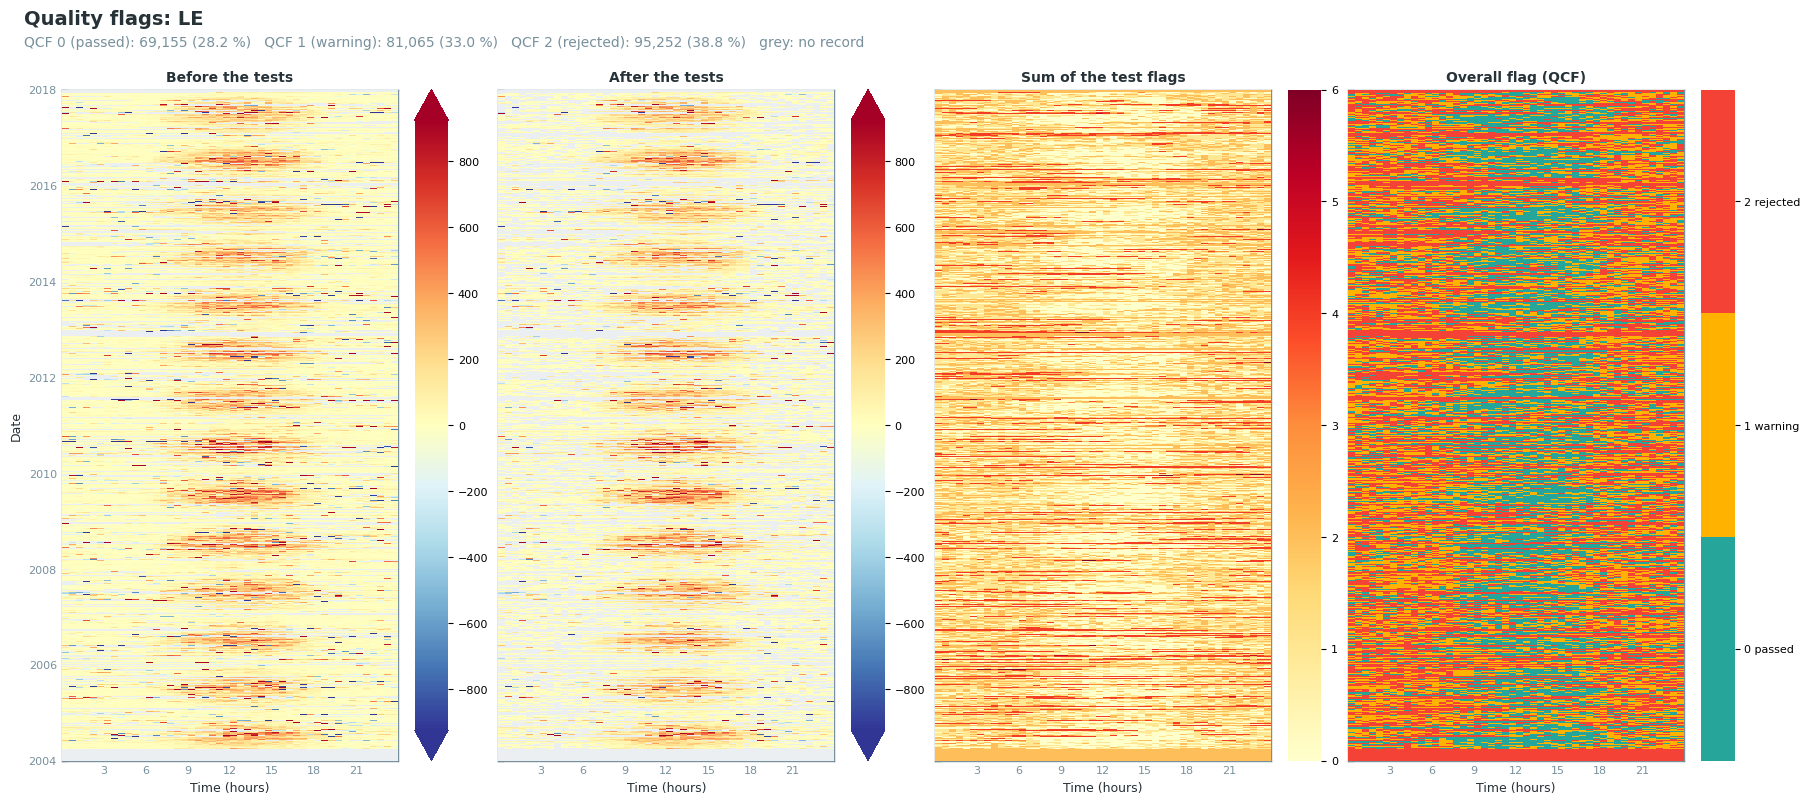

In [6]:
data.levels.level2_qcf.showplot_qcf_heatmaps()

### 📋 Table: result of each Level-2 test

In [7]:
data.levels.level2_qcf.report_qcf_flags()

Test flags: LE
Measured records: 200,208 of 245,472
Missing records: 45,264 (18.44 %), flagged by the missing-values test
                                                  Pass     Warn     Fail    Fail      Not
Test                        Period    Tested       (0)      (1)      (2)       %   tested
─────────────────────────────────────────────────────────────────────────────────────────
L2_LE_SSITC                 all      200,208    70,775   85,153   44,280   22.12        0
                            day      101,589    49,762   37,580   14,247   14.02        0
                            night     98,619    21,013   47,573   30,033   30.45        0
                                                                                         
L2_LE_SCF                   all      200,208   200,208        0        0    0.00        0
                            day      101,589   101,589        0        0    0.00        0
                            night     98,619    98,619        0        0    0.00        0
                                                                                         
L2_LE_SIGNAL_STRENGTH       all      200,208   191,808        0    8,400    4.20        0
                            day      101,589    97,767        0    3,822    3.76        0
                            night     98,619    94,041        0    4,578    4.64        0
                                                                                         
L2_LE_H2O_VM97_SPIKE_HF     all      200,208   198,829        0    1,379    0.69        0
                            day      101,589   101,052        0      537    0.53        0
                            night     98,619    97,777        0      842    0.85        0
                                                                                         
L2_LE_H2O_VM97_DROPOUT_HF   all      200,208   200,208        0        0    0.00        0
                            day      101,589   101,589        0        0    0.00        0
                            night     98,619    98,619        0        0    0.00        0

## Step 3: no storage term (Level 3.1)

No storage term is added: FLUXNET2015 and ONEFlux take LE as a turbulent flux without storage
correction (Pastorello et al. 2020). Level 3.1 runs with `set_storage_to_zero=True`, because the
later levels need it ([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#storage-term)).

In [8]:
data = run_level31(data, set_storage_to_zero=True)
print(f'After L3.1: {data.filteredseries.dropna().count():,} valid records '
      f'(col: {data.filteredseries.name})')

────────────────────────────────── Level 3.1: Storage Correction ───────────────────────────────────

> Calculating storage-corrected flux LE_L3.1 from flux LE + storage term set to zero

After L3.1: 150,220 valid records (col: LE_L3.1_QCF)


## Step 4: outlier removal (Level 3.2)

Four tests. Check each plot, then accept the test with `sod.addflag()` in the cell below it.

1. Periods in `REMOVE_DATES`, removed by hand; the reasons are in the site documentation.
2. Absolute limits `ABSLIM`.
3. Hampel filter on double differences: single spikes.
4. Hampel filter per time of day: values wrong for their time of day.

Negative values at night are not tested: LE can be negative at night (dew). How the tests work: [diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#outlier-tests). The table at the end of this step lists
further tests.

In [9]:
data, sod = make_level32_detector(data)

### 📊 Plot: periods removed by hand

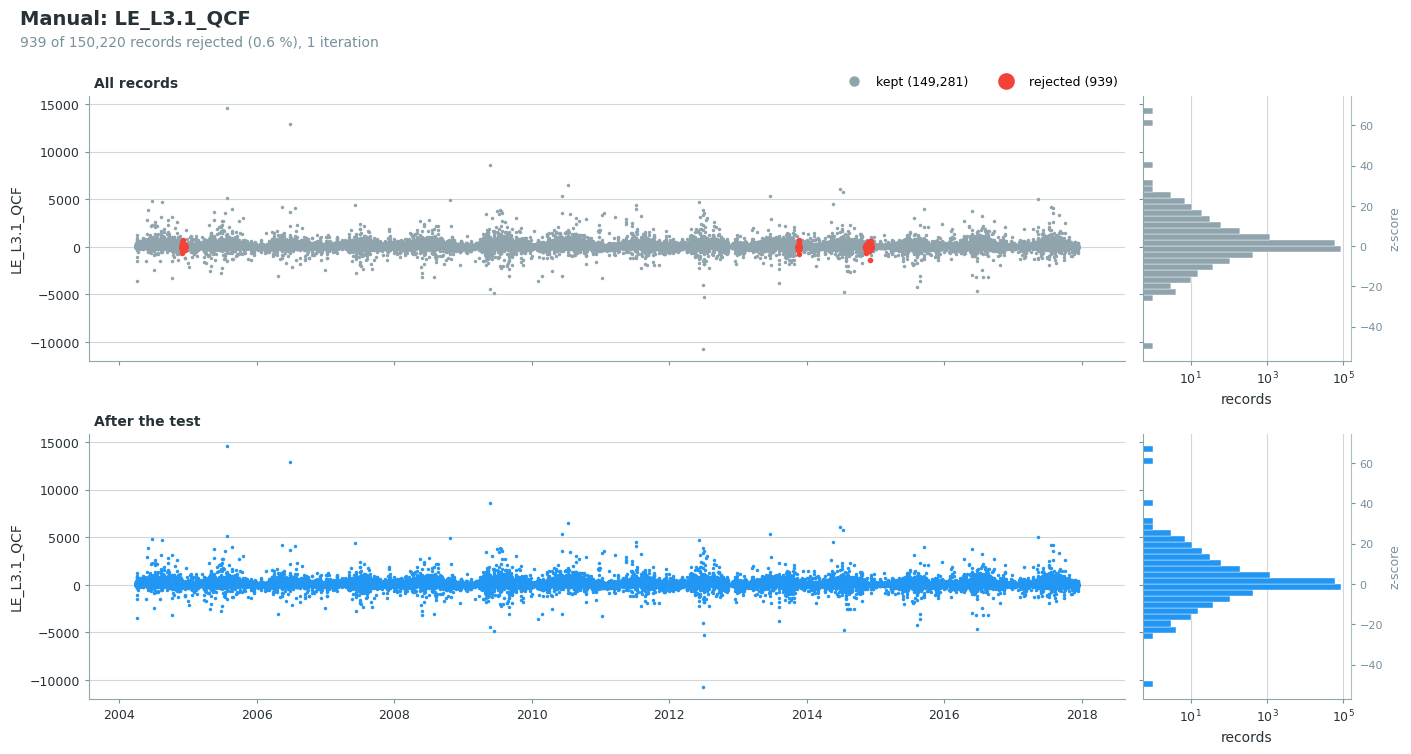

In [10]:
# Only the date ranges that overlap the processed records; none means no test and no flag.
_first, _last = data.full_df.index[0], data.full_df.index[-1]
_remove = [_d for _d in REMOVE_DATES
           if pd.Timestamp(_d[0]) <= _last and pd.Timestamp(_d[1]) + pd.Timedelta('1D') > _first]
if _remove:
    sod.flag_manualremoval_test(remove_dates=_remove, showplot=True, verbose=True)
else:
    print(f"No manual removal dates in {_first:%Y-%m-%d} - {_last:%Y-%m-%d}; test skipped.")

In [11]:
if _remove:
    sod.addflag()  # accept the manual removal

> ++Added flag column FLAG_L3.2_LE_L3.1_QCF_OUTLIER_MANUAL_TEST to flag data

### 📊 Plot: absolute limits

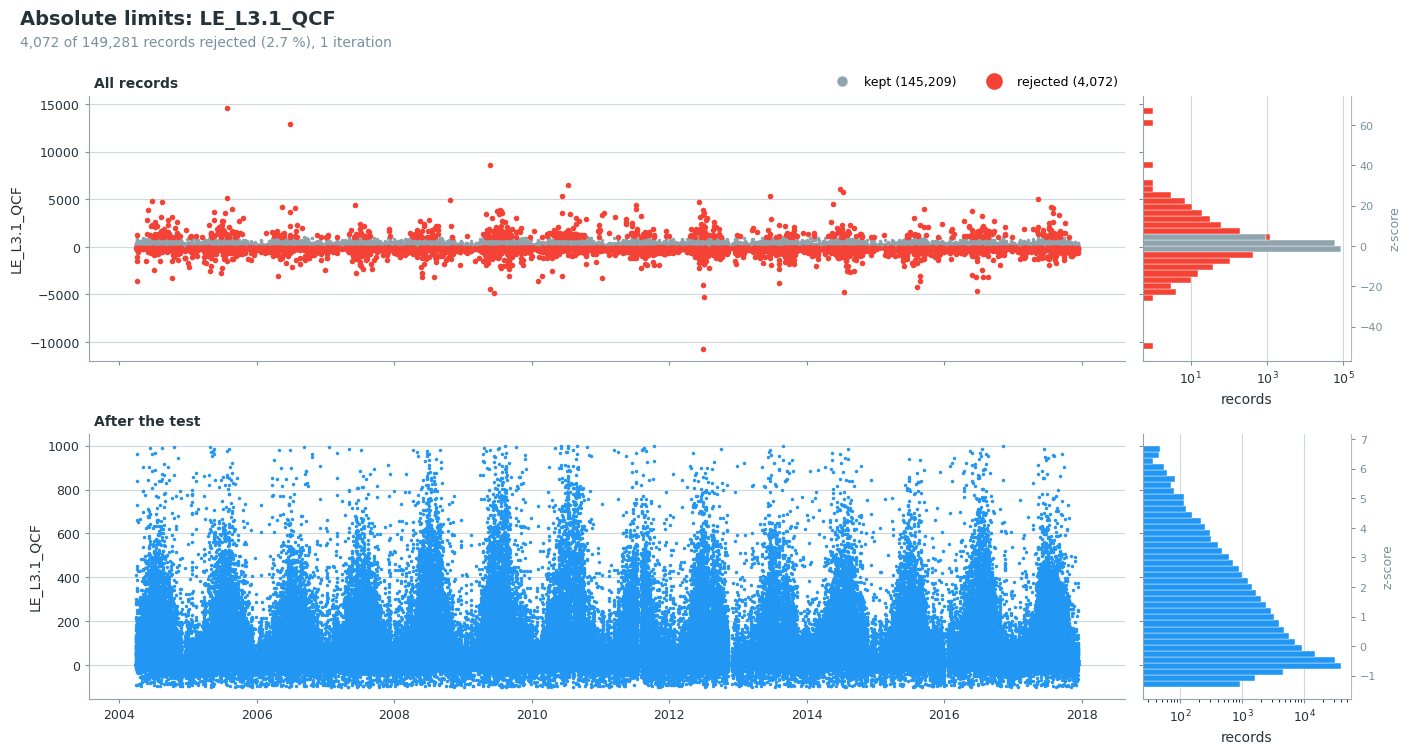

In [12]:
sod.flag_outliers_abslim_test(minval=ABSLIM[0], maxval=ABSLIM[1], showplot=True, verbose=True)

In [13]:
sod.addflag()  # accept this test

> ++Added flag column FLAG_L3.2_LE_L3.1_QCF_OUTLIER_ABSLIM_TEST to flag data

### 📊 Plot: Hampel filter on double differences

[Dt/Nt] ITER #01 | Outliers:  4438 (  3.06%) | Day:  1562 | Night:  2876

[Dt/Nt] ITER #02 | Outliers:   650 (  0.46%) | Day:   180 | Night:   470

[Dt/Nt] ITER #03 | Outliers:   128 (  0.09%) | Day:    26 | Night:   102

[Dt/Nt] ITER #04 | Outliers:    26 (  0.02%) | Day:     5 | Night:    21

[Dt/Nt] ITER #05 | Outliers:     5 (  0.00%) | Day:     2 | Night:     3

[Dt/Nt] ITER #06 | Outliers:     4 (  0.00%) | Day:     4 | Night:     0

[Dt/Nt] ITER #07 | Outliers:     1 (  0.00%) | Day:     1 | Night:     0

[Dt/Nt] ITER #08 | Outliers:     0 (  0.00%) | Day:     0 | Night:     0

! Hampel: 48 record(s) could not be judged because the local MAD was exactly zero (more than half 
the window identical) and were left unflagged. Typical causes: coarser data upsampled onto a finer 
grid, quantized readings, or a stuck sensor. Consider a longer window_length, 
use_differencing=False, or screening the affected period separately.

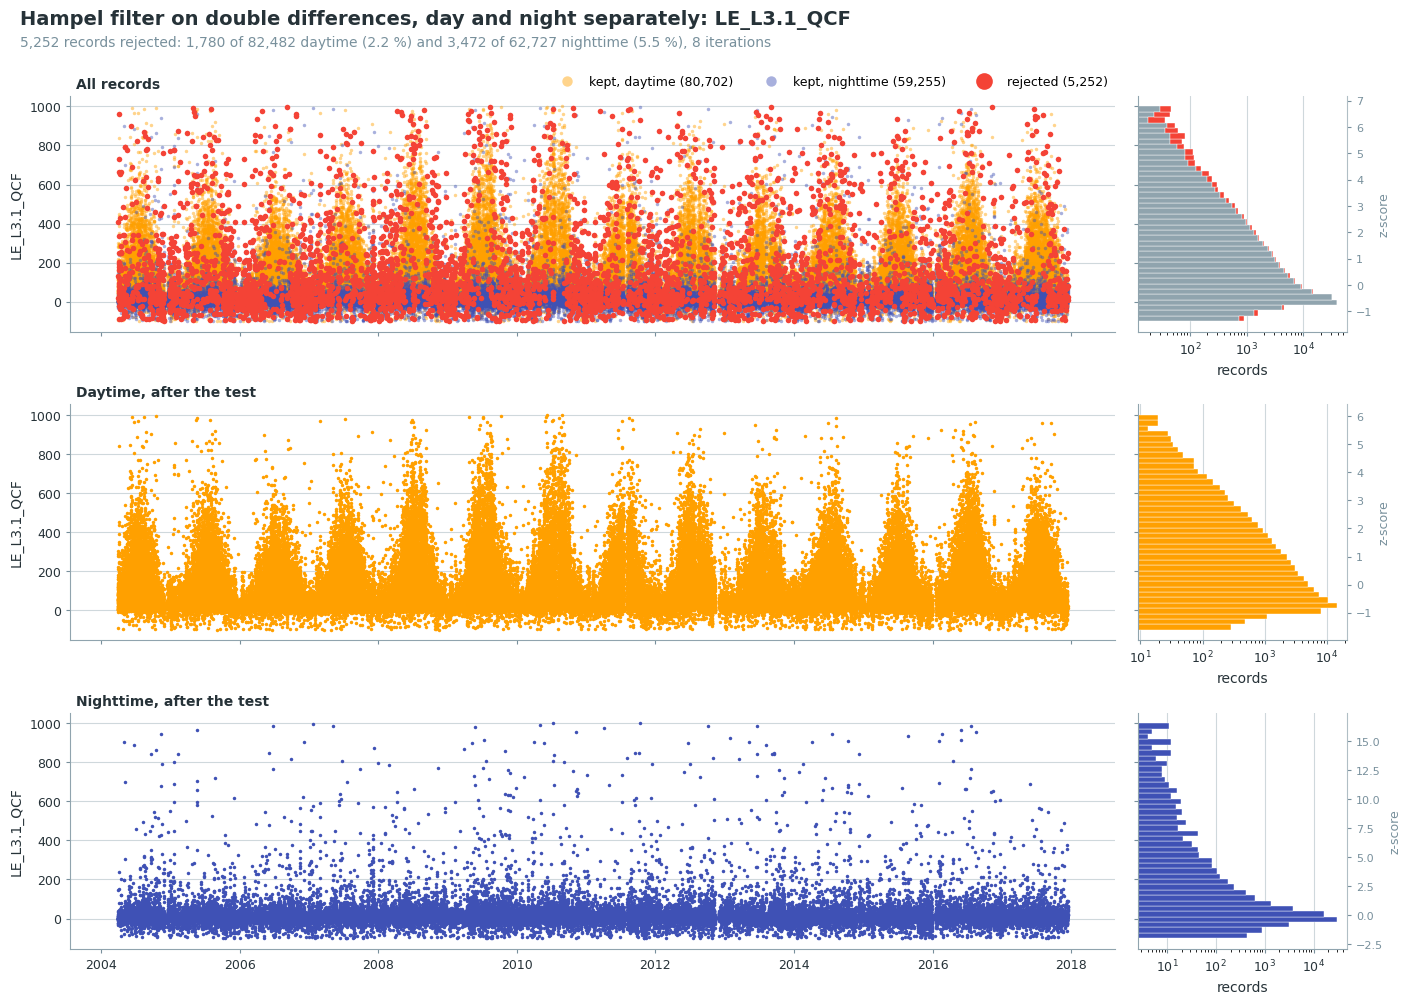

In [14]:
sod.flag_outliers_hampel_test(window_length=48 * 13, n_sigma=5.5, use_differencing=True,
                              separate_day_night=True, showplot=True, verbose=True, repeat=True)

In [15]:
sod.addflag()  # accept this test

> ++Added flag column FLAG_L3.2_LE_L3.1_QCF_OUTLIER_HAMPEL_TEST to flag data

### 📊 Plot: Hampel filter on values per time of day

[Dt/Nt] ITER #01 | Outliers:  4212 (  3.01%) | Day:  1344 | Night:  2868

[Dt/Nt] ITER #02 | Outliers:   646 (  0.48%) | Day:   181 | Night:   465

[Dt/Nt] ITER #03 | Outliers:   128 (  0.09%) | Day:    33 | Night:    95

[Dt/Nt] ITER #04 | Outliers:    23 (  0.02%) | Day:     1 | Night:    22

[Dt/Nt] ITER #05 | Outliers:     6 (  0.00%) | Day:     1 | Night:     5

[Dt/Nt] ITER #06 | Outliers:     0 (  0.00%) | Day:     0 | Night:     0

! Hampel: 750 record(s) were not tested because their time-of-day window held fewer than 
min_records=10 values. They keep flag 0. Consider a longer window_length or more time_of_day_slots.

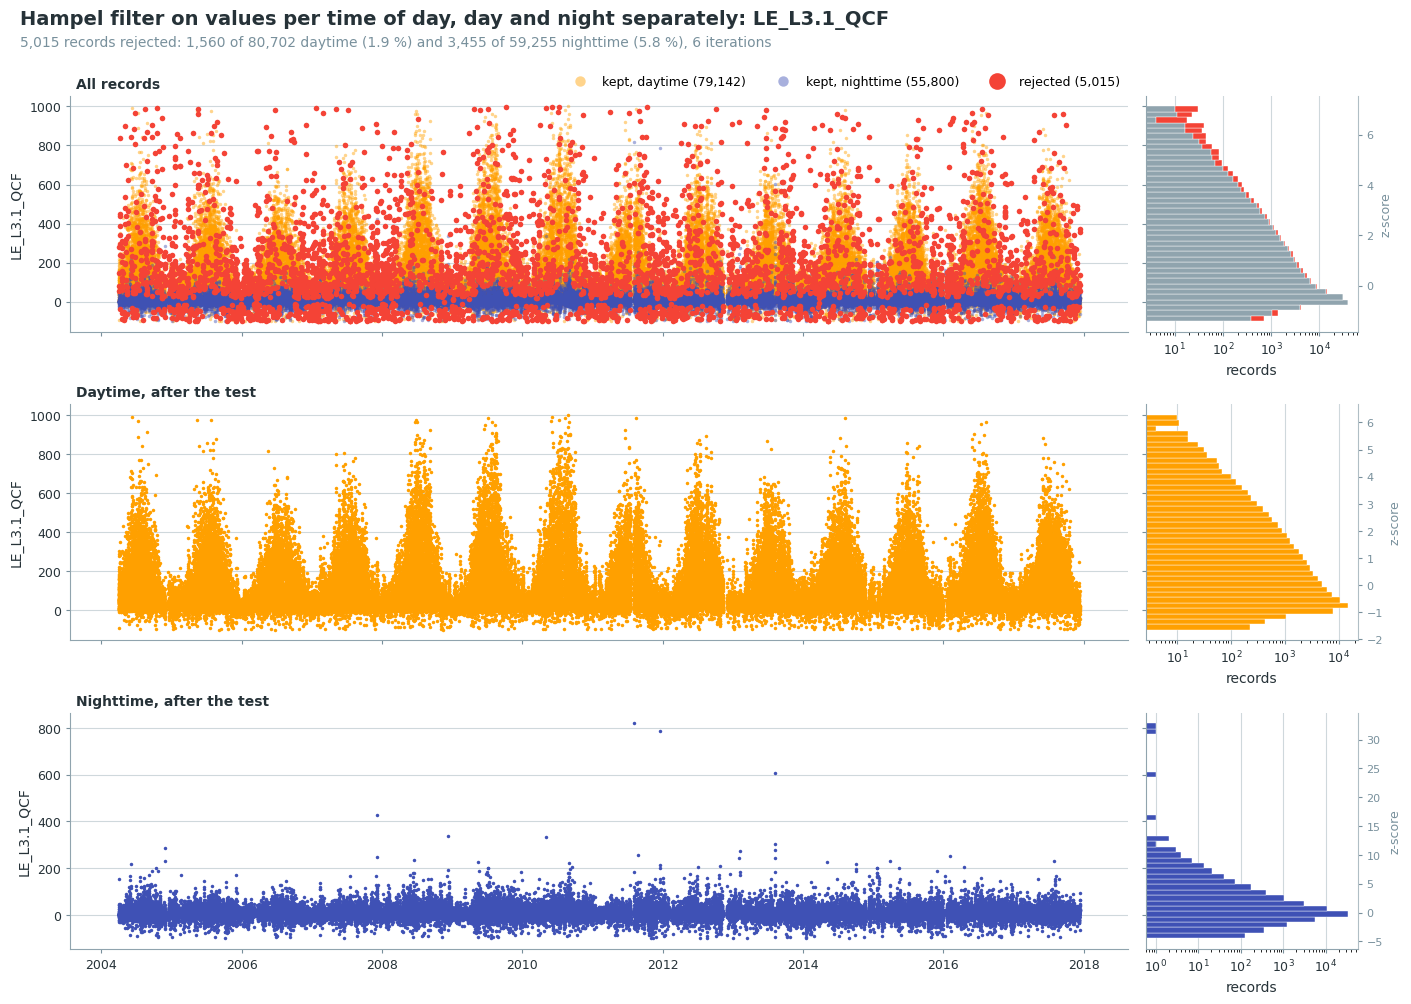

In [16]:
sod.flag_outliers_hampel_test(window_length=48 * 13, n_sigma=5.5, use_differencing=False,
                              by_time_of_day=True, time_of_day_slots=1, min_records=10,
                              separate_day_night=True, showplot=True, verbose=True, repeat=True)

In [17]:
sod.addflag()  # accept this test

> ++Added flag column FLAG_L3.2_LE_L3.1_QCF_OUTLIER_HAMPEL_2_TEST to flag data

### 📋 Table: outlier tests available in diive

Every test of the outlier detector `sod`, with the ones used above marked. `help(sod.<method>)`
shows the settings of a test.

In [18]:
_used = {'flag_manualremoval_test', 'flag_outliers_abslim_test', 'flag_outliers_hampel_test'}
_rows = []
for _name in sorted(dir(type(sod))):
    if not (_name.startswith('flag_') and _name.endswith('_test')):
        continue
    # The first sentence of the docstring, which may run over two lines.
    _doc = (getattr(type(sod), _name).__doc__ or '').strip().split('\n\n')[0]
    _first = ' '.join(_doc.split()).split('. ')[0].rstrip('.')
    _rows.append({'method': f'sod.{_name}()', 'what it does': _first,
                  'used here': 'yes' if _name in _used else ''})
display(pd.DataFrame(_rows).set_index('method'))

,what it does,used here
method,,
sod.flag_manualremoval_test(),Flag specified records for removal,yes
sod.flag_missingvals_test(),Flag missing records in the data (flag 2 where...,
sod.flag_outliers_abslim_test(),Identify outliers based on absolute limits,yes
sod.flag_outliers_hampel_test(),Identify outliers in a sliding window based on...,yes
sod.flag_outliers_increments_zcore_test(),Identify outliers based on the z-score of reco...,
sod.flag_outliers_localsd_test(),Identify outliers based on standard deviation ...,
sod.flag_outliers_lof_test(),Local outlier factor detection (global or sepa...,
sod.flag_outliers_negative_night_test(),Flag nighttime values below -z times their ran...,
sod.flag_outliers_negative_nights_test(),Flag all records of nights whose median lies b...,


### Apply the Level-3.2 flags

In [19]:
data = run_level32(data, outlier_detector=sod)
print(f'After L3.2: {data.filteredseries.dropna().count():,} valid records')

────────────────────────────── Level 3.2: Stepwise Outlier Detection ───────────────────────────────

After L3.2: 134,942 valid records


### 📊 Plot: all removed outliers

Every record Level 3.2 removed, coloured by the test that removed it, with the share removed per
month and per hour of the day.

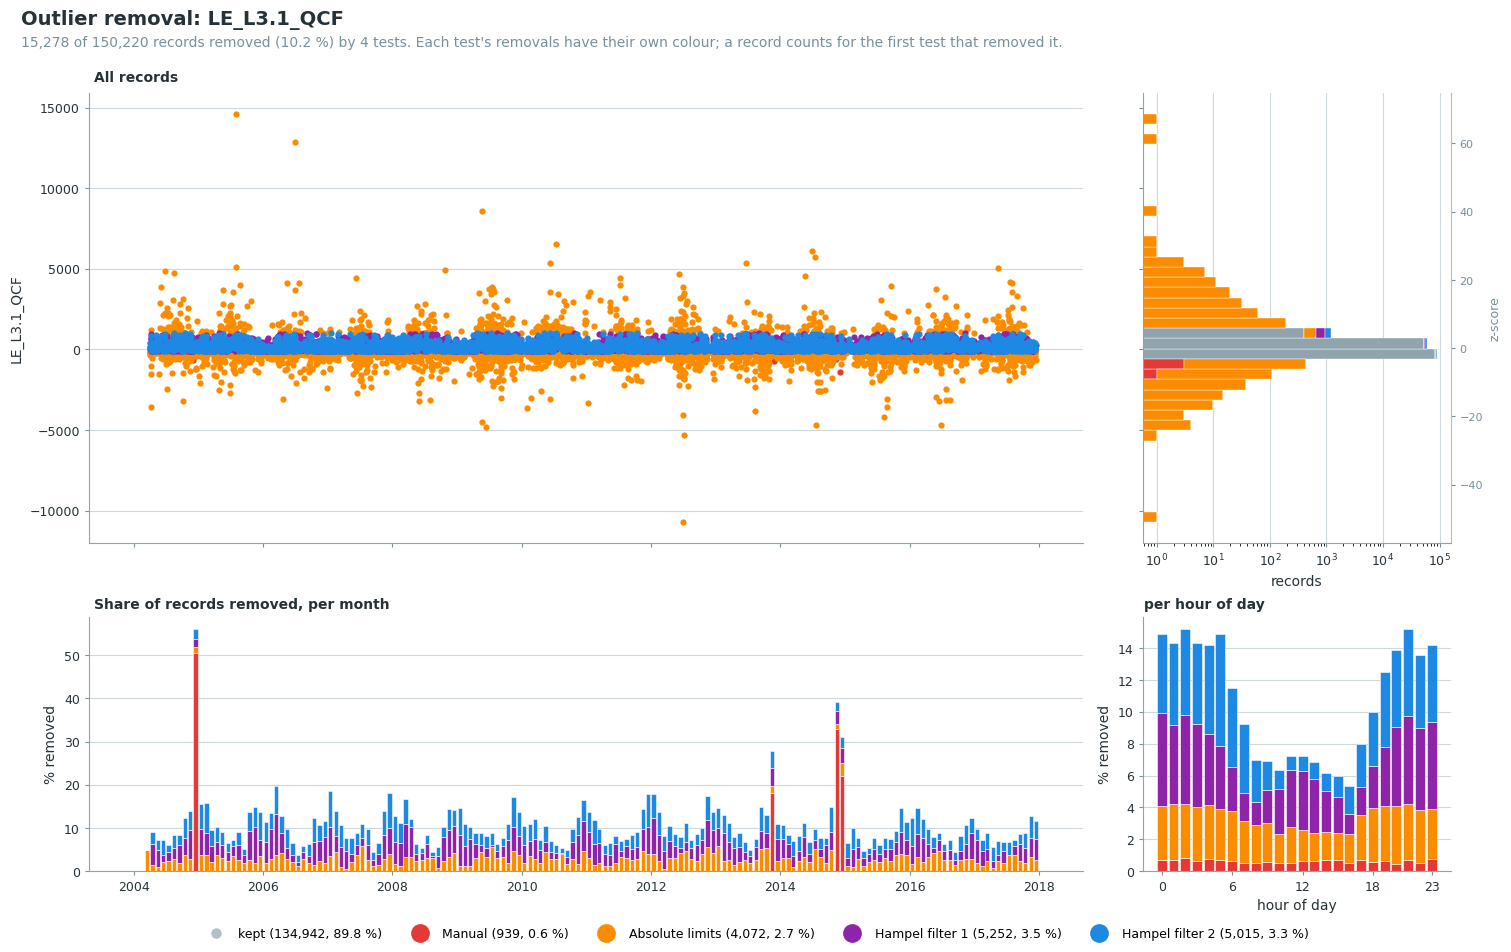

In [20]:
data.levels.level32.showplot_overview();

### 📊 Plot: Level-3.2 quality flag over time

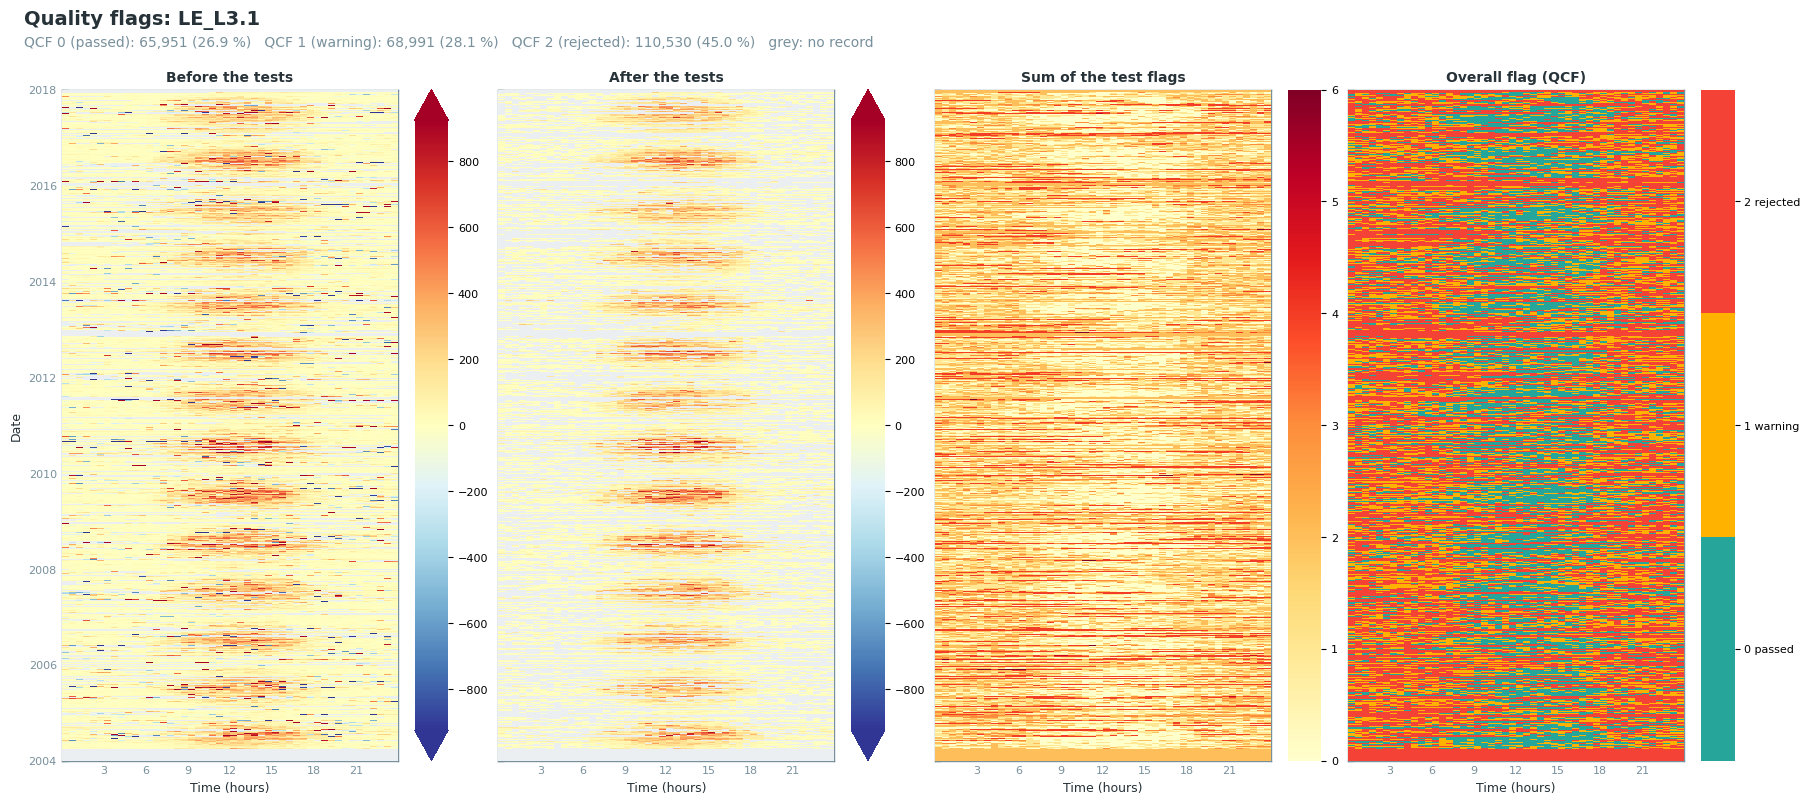

In [21]:
data.levels.level32_qcf.showplot_qcf_heatmaps()

### 📋 Table: result of each Level-3.2 test

In [22]:
data.levels.level32_qcf.report_qcf_flags()

Test flags: LE_L3.1
Measured records: 200,208 of 245,472
Missing records: 45,264 (18.44 %), flagged by the missing-values test
                                                          Pass     Warn     Fail    Fail      Not
Test                                Period    Tested       (0)      (1)      (2)       %   tested
─────────────────────────────────────────────────────────────────────────────────────────────────
L2_LE_SSITC                         all      200,208    70,775   85,153   44,280   22.12        0
                                    day      101,589    49,762   37,580   14,247   14.02        0
                                    night     98,619    21,013   47,573   30,033   30.45        0
                                                                                                 
L2_LE_SCF                           all      200,208   200,208        0        0    0.00        0
                                    day      101,589   101,589        0        0    0.00        0
                                    night     98,619    98,619        0        0    0.00        0
                                                                                                 
L2_LE_SIGNAL_STRENGTH               all      200,208   191,808        0    8,400    4.20        0
                                    day      101,589    97,767        0    3,822    3.76        0
                                    night     98,619    94,041        0    4,578    4.64        0
                                                                                                 
L2_LE_H2O_VM97_SPIKE_HF             all      200,208   198,829        0    1,379    0.69        0
                                    day      101,589   101,052        0      537    0.53        0
                                    night     98,619    97,777        0      842    0.85        0
                                                                                                 
L2_LE_H2O_VM97_DROPOUT_HF           all      200,208   200,208        0        0    0.00        0
                                    day      101,589   101,589        0        0    0.00        0
                                    night     98,619    98,619        0        0    0.00        0
                                                                                                 
L3.2_LE_L3.1_QCF_OUTLIER_MANUAL     all      150,220   149,281        0      939    0.63   49,988
                                    day       84,715    84,342        0      373    0.44   16,874
                                    night     65,505    64,939        0      566    0.86   33,114
                                                                                                 
L3.2_LE_L3.1_QCF_OUTLIER_ABSLIM     all      149,281   145,209        0    4,072    2.73   50,927
                                    day       84,342    82,482        0    1,860    2.21   17,247
                                    night     64,939    62,727        0    2,212    3.41   33,680
                                                                                                 
L3.2_LE_L3.1_QCF_OUTLIER_HAMPEL     all      145,209   139,957        0    5,252    3.62   54,999
                                    day       82,482    80,702        0    1,780    2.16   19,107
                                    night     62,727    59,255        0    3,472    5.54   35,892
                                                                                                 
L3.2_LE_L3.1_QCF_OUTLIER_HAMPEL_2   all      139,957   134,942        0    5,015    3.58   60,251
                                    day       80,702    79,142        0    1,560    1.93   20,887
                                    night     59,255    55,800        0    3,455    5.83   39,364

## Step 5: no USTAR filter (Level 3.3)

No USTAR filter for LE, as in FLUXNET2015 and ONEFlux (Pastorello et al. 2020). The gap-filling
needs Level 3.3, so it runs one scenario, `CUT_NONE`, with a threshold of 0, which removes no record
([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#ustar-filter)).

In [23]:
data = run_level33_constant_ustar(
    data,
    thresholds=USTAR_THRESHOLDS,
    threshold_labels=USTAR_SCENARIOS,
    showplot=False,
    verbose=True,
)

──────────────────────────────────── Level 3.3: USTAR Filtering ────────────────────────────────────

> QCF computed for USTAR scenario CUT_NONE

### Records for gap-filling and highest-quality records

The records the gap-filling starts from (QCF 0 and 1, columns `_QCF`) and the highest-quality
records (QCF 0, columns `_QCF0`) for analyses without gap-filled values
([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#gapfilling-input)).

### 📋 Table: records for gap-filling

In [24]:
report_gapfilling_input(data);

Records for gap-filling
                      removed:   removed:              used:    used:    used:    used:
USTAR      measured      tests      USTAR      used    QCF 0    QCF 1      day    night
───────────────────────────────────────────────────────────────────────────────────────
CUT_NONE    200,208     65,266          0   134,942   65,951   68,991   79,142   55,800
                82%        27%         0%       55%      27%      28%      32%      23%
Records, and their share of all 245,472 records of the period.
removed: tests = quality tests and outlier detection (Levels 2 to 3.2).
used = records for gap-filling: QCF below 2 by day and below 2 by night. QCF 0 is the highest 
quality, the measured flux for analyses without gap-filled values.

### 📊 Plot: records for gap-filling and highest-quality records

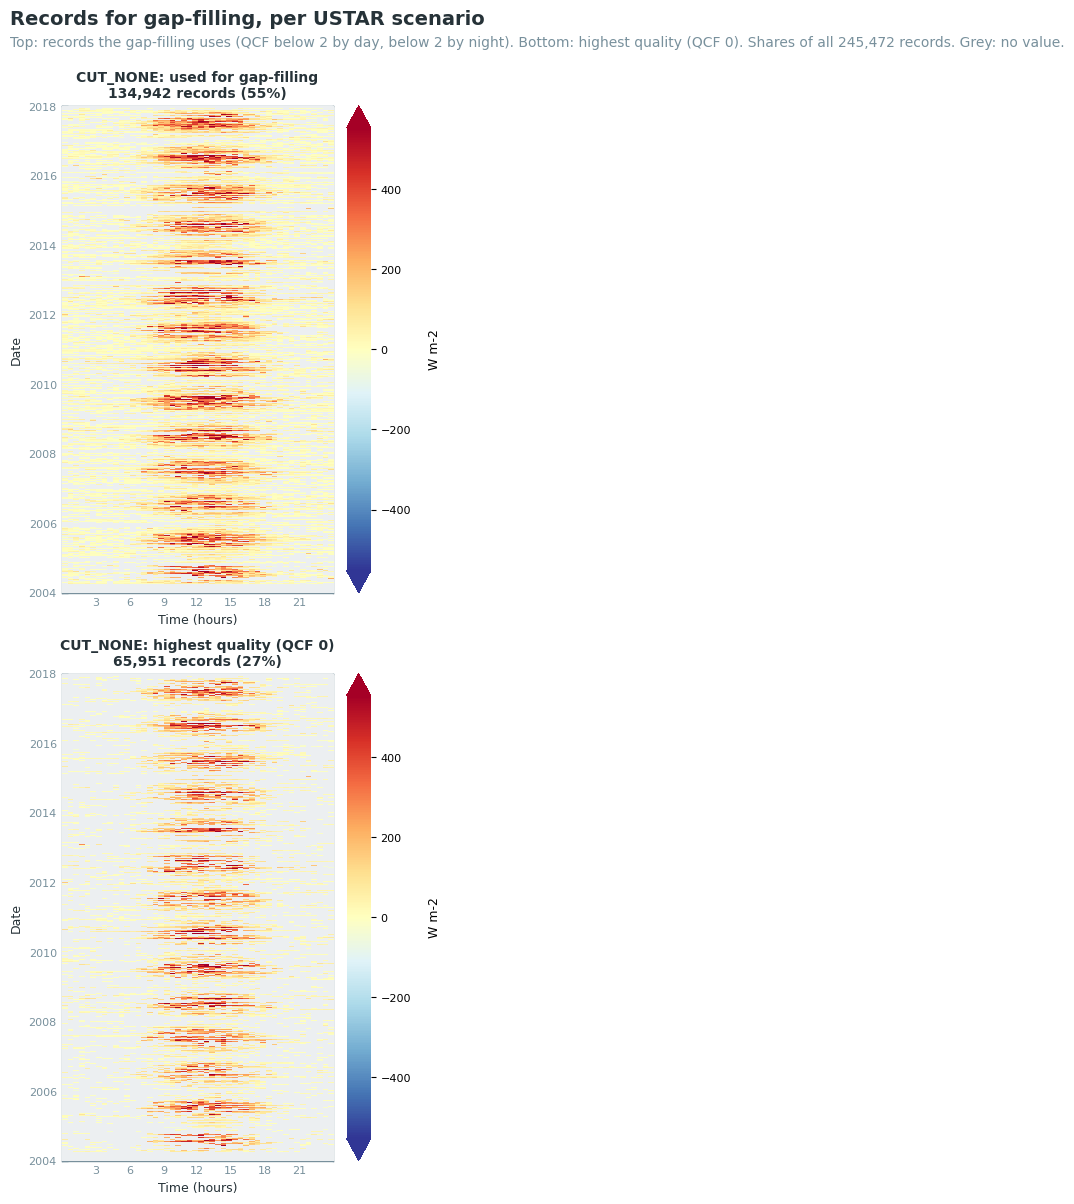

In [25]:
plot_gapfilling_input(data, units=FLUX_UNITS)

### 📋 Table: gaps

The gaps left after Level 3.3, which the gap-filling has to fill. A long gap lasts at least one day.

In [26]:
report_gaps(data, long_gap_days=1);

Gaps to fill
USTAR      missing %    gaps   long gaps   longest gap (days)   worst month   worst month missing %
───────────────────────────────────────────────────────────────────────────────────────────────────
CUT_NONE        45.0   29001         215                 90.5           Jan                    59.1
A long gap lasts at least 1 day.

## Step 6: model features

The feature engineer adds lagged values, rolling statistics and time terms to the drivers. It is
built once and passed to XGBoost. `target_col` is only a placeholder.

In [27]:
engineer = FeatureEngineer(
    target_col='_target_',
    features_lag=[-2, 2],
    features_lag_stepsize=1,
    features_rolling=[2, 4, 12, 24, 48],
    features_rolling_stats=['median', 'min', 'max', 'std'],
    features_ema=[6, 12, 24, 48],
    vectorize_timestamps=True,
    add_continuous_record_number=True,
    sanitize_timestamp=True,
    verbose=0,
)

## Step 7: gap-filling (Level 4.1)

XGBoost fills the gaps of this dataset, MDS for comparison (Step 10).

### XGBoost

One model per year, trained on three years, with features selected by SHAP
([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#xgboost-gapfilling)).

The number of trees is chosen once for all models by blocked cross-validation
([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#tree-selection)).

In [28]:
data = run_level41_xgb(
    data,
    features=FEATURES,
    engineer=engineer,
    reduce_features=True,
    n_estimators_cv=True,
    verbose=1,
    **XGB_SETTINGS,
)

───────────────────────────────── Level 4.1: Gap-Filling (XGBoost) ─────────────────────────────────

### MDS

Marginal distribution sampling (Reichstein et al. 2005) in `mode='diive'`, filling every gap from
measured driver values only ([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#mds-gapfilling)).

**Skipped** when `RUN_MDS = False`.

In [29]:
if RUN_MDS:
    data = run_level41_mds(
        data,
        swin=SW_IN_F, ta=TA_F, vpd=VPD_F,  # W m-2, degC, kPa
        swin_qc=SW_IN_FLAG, ta_qc=TA_FLAG, vpd_qc=VPD_FLAG,
        **MDS_SETTINGS,
    )

─────────────────────────────────── Level 4.1: Gap-Filling (MDS) ───────────────────────────────────

## Step 8: results

How many records were measured and how many were filled, then the annual sum of LE in MJ m-2, for
each gap-filling method. The share measured is given in brackets: a year with long gaps rests
largely on the model. An incomplete year is marked.

### 📋 Table: measured and filled records

In [30]:
report_gapfilling_variables(data)

Gap-filled variables
method    USTAR      records   measured    filled   filled %
────────────────────────────────────────────────────────────
MDS       CUT_NONE   245,472    134,942   110,530       45.0
XGBoost   CUT_NONE   245,472    134,942   110,530       45.0
MDS (CUT_NONE): LE_L3.1_L3.3_CUT_NONE_QCF -> LE_L3.1_L3.3_CUT_NONE_QCF_gfMDS
XGBoost (CUT_NONE): LE_L3.1_L3.3_CUT_NONE_QCF -> LE_L3.1_L3.3_CUT_NONE_QCF_gfXG

### 📋 Table: annual sums of LE

In [31]:
report_annual_sums(data, gain=W_TO_MJ, units='MJ m-2');

Annual sums (MJ m-2)
               MDS       XGBoost
year      CUT_NONE      CUT_NONE
────────────────────────────────
2004   1,926 (43%)   1,846 (43%)
2005   1,770 (57%)   1,718 (57%)
2006   1,447 (58%)   1,549 (58%)
2007   1,647 (58%)   1,693 (58%)
2008   1,965 (57%)   2,061 (57%)
2009   2,096 (58%)   2,160 (58%)
2010   2,200 (54%)   2,266 (54%)
2011   1,747 (57%)   1,791 (57%)
2012   1,870 (50%)   1,903 (50%)
2013   1,701 (52%)   1,721 (52%)
2014   1,672 (55%)   1,714 (55%)
2015   1,645 (56%)   1,697 (56%)
2016   1,835 (57%)   1,906 (57%)
2017   1,744 (57%)   1,784 (57%)
In brackets: the share of the year's records that were measured.

## Step 9: model quality

First the scores on test data: a random 25 % of the complete records, which the model did not see in
training. The number of trees is chosen without the test data. Because the test
records lie between training records, the scores describe short gaps better than gaps of several
days.

### 📋 Table: scores on test data

In [32]:
report_traintest_model_scores(data)

Held-out test scores
method    USTAR      year      R²    RMSE     MAE   MedAE    MaxE
─────────────────────────────────────────────────────────────────
XGBoost   CUT_NONE   2004   0.725   57.42   33.02   16.61   852.6
XGBoost   CUT_NONE   2005   0.725   57.42   33.02   16.61   852.6
XGBoost   CUT_NONE   2006   0.734   55.38   31.69   15.55   835.1
XGBoost   CUT_NONE   2007   0.757   57.19   33.04   16.17   608.9
XGBoost   CUT_NONE   2008   0.768   63.28   36.19   17.17   653.6
XGBoost   CUT_NONE   2009   0.776   68.07   39.20   18.68   724.9
XGBoost   CUT_NONE   2010   0.766   66.43   37.76   18.79   795.4
XGBoost   CUT_NONE   2011   0.752   65.70   36.91   18.48   807.8
XGBoost   CUT_NONE   2012   0.728   61.88   35.08   17.75   805.1
XGBoost   CUT_NONE   2013   0.734   60.75   35.50   18.35   769.5
XGBoost   CUT_NONE   2014   0.752   56.00   34.29   18.69   410.8
XGBoost   CUT_NONE   2015   0.765   57.19   34.89   18.78   632.1
XGBoost   CUT_NONE   2016   0.777   56.10   34.14   18.08   619.8
XGBoost   CUT_NONE   2017   0.777   56.10   34.14   18.08   619.8
XGBoost   CUT_NONE   mean   0.753   59.92   34.92   17.70   713.4
Test set: a random share of the complete records, not used in training.
Errors are in the units of the flux.
Not available for MDS (CUT_NONE).

### 📋 Table: gap-filling models per year

How each model was built and how well it did: the years it was trained on, its features, the
training and test records, the number of trees, the records of the final fit,
the test scores, and how the gaps of its year were filled.

In [33]:
report_model_overview(data);

Gap-filling models
                  trained                                          final    test    test            fall-
USTAR      year   on          features    train    test   trees      fit      R²    RMSE   filled    back
─────────────────────────────────────────────────────────────────────────────────────────────────────────
CUT_NONE   2004   2004-2006         82   20,731   6,830     110   27,561   0.725   57.42   10,007       0
CUT_NONE   2005   2004-2006         82   20,731   6,830     110   27,561   0.725   57.42    7,609       0
CUT_NONE   2006   2005-2007         82   22,704   7,462     110   30,166   0.734   55.38    7,431       0
CUT_NONE   2007   2006-2008         82   22,899   7,448     110   30,347   0.757   57.19    7,354       0
CUT_NONE   2008   2007-2009         82   22,904   7,441     110   30,345   0.768   63.28    7,476       0
CUT_NONE   2009   2008-2010         82   22,343   7,305     110   29,648   0.776   68.07    7,433       0
CUT_NONE   2010   2009-2011         82   22,126   7,385     110   29,511   0.766   66.43    8,051       0
CUT_NONE   2011   2010-2012         82   21,097   7,136     110   28,233   0.752   65.70    7,565       0
CUT_NONE   2012   2011-2013         82   20,862   7,054     110   27,916   0.728   61.88    8,759       0
CUT_NONE   2013   2012-2014         82   20,624   7,029     110   27,653   0.734   60.75    8,368       0
CUT_NONE   2014   2013-2015         82   21,477   7,255     110   28,732   0.752   56.00    7,828       0
CUT_NONE   2015   2014-2016         82   22,155   7,480     110   29,635   0.765   57.19    7,632       0
CUT_NONE   2016   2015-2017         82   22,407   7,552     110   29,959   0.777   56.10    7,513       0
CUT_NONE   2017   2015-2017         82   22,407   7,552     110   29,959   0.777   56.10    7,504       0
Each year has its own model, trained on that year and its neighbours ('trained on').
train / test: a random 75 / 25 % split of the complete records; the test scores come from the 25 %, which
the model did not see.
trees: 110 for every model, chosen by blocked cross-validation (report_tree_selection).
final fit: the gaps are filled by a model refitted on all complete records with that number of trees. 
filled / fallback: gaps of the model year filled by this model, or by the fallback model on timestamp 
features where a driver was missing.
XGBoost: learning_rate=0.05, max_depth=6, n_estimators=110, n_jobs=-1, random_state=42

### 📋 Table: number of trees from blocked cross-validation

The scores on held-out blocks of days at the chosen number of trees, next to the scores on the
random test records. The blocked scores describe gaps of days, the random ones single missing
records ([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#tree-selection)).

In [34]:
report_tree_selection(data);

Number of trees from blocked cross-validation
                      blocked   blocked   blocked   random   random
pool        records      RMSE       MAE        R²     RMSE       R²
───────────────────────────────────────────────────────────────────
2004-2006    20,731     61.56     35.60     0.694    57.42    0.725
2005-2007    22,704     59.41     34.30     0.697    55.38    0.734
2006-2008    22,899     61.03     35.27     0.729    57.19    0.757
2007-2009    22,904     68.09     39.39     0.730    63.28    0.768
2008-2010    22,343     75.53     43.60     0.721    68.07    0.776
2009-2011    22,126     72.39     41.97     0.719    66.43    0.766
2010-2012    21,097     69.97     40.38     0.716    65.70    0.752
2011-2013    20,862     64.26     37.34     0.700    61.88    0.728
2012-2014    20,624     65.87     38.44     0.686    60.75    0.734
2013-2015    21,477     62.86     37.01     0.686    56.00    0.752
2014-2016    22,155     63.98     37.88     0.714    57.19    0.765
2015-2017    22,407     62.04     36.85     0.734    56.10    0.777
110 trees for every model: the minimum of the median error curve of the pools, rounded to ten (up to
1000 tested). USTAR scenario CUT_NONE.
blocked: 5-fold cross-validation on the training records of each pool, holding out whole 14-day 
blocks, at the chosen number of trees. R² from the RMSE and the variance of the target.
random: the test records of the models of that pool, random single half-hours that the models did 
not see. The difference shows how much harder gaps of days are than single missing records.

### 📊 Plot: number of trees from blocked cross-validation

The error on held-out blocks against the number of trees, one line per pool, and the chosen
number. The curves should flatten well before the largest number tested.

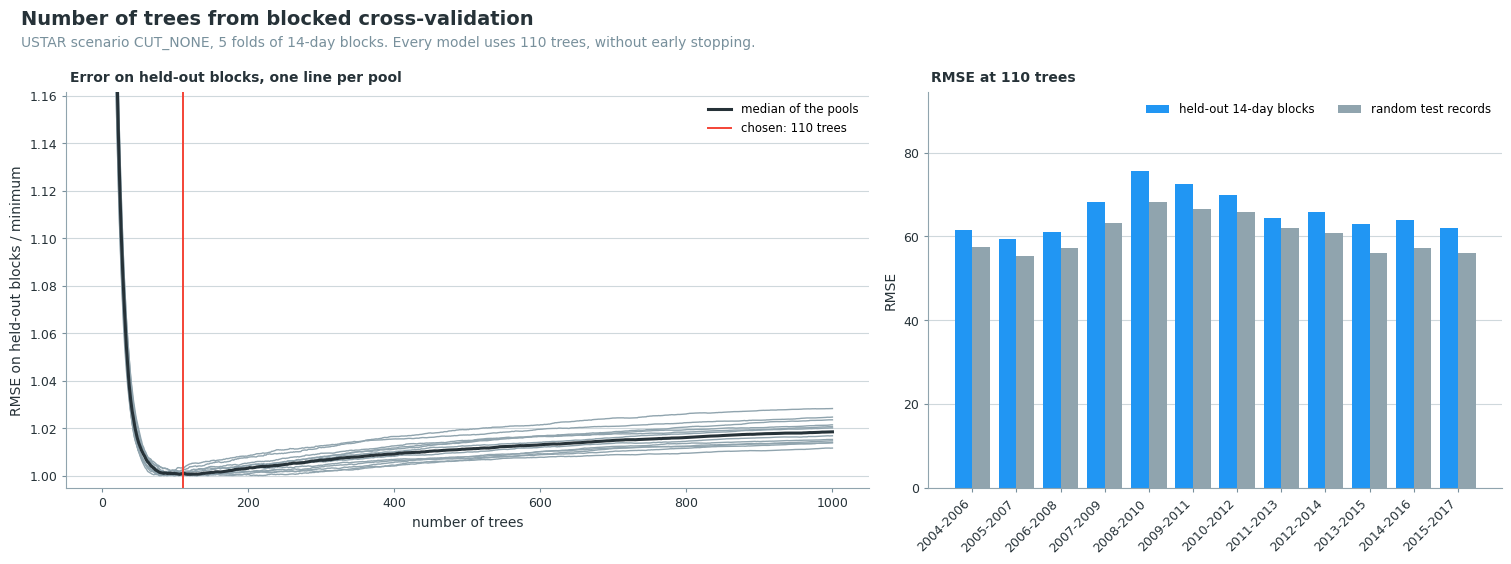

In [35]:
plot_tree_selection(data);

Next the scores on all measured records. The gaps are filled by a model refitted on all of them, so
these scores are better than the test scores and only show how closely the model fits.

### 📋 Table: scores on all measured records

In [36]:
report_gapfilling_model_scores(data)

In-sample scores
method    USTAR      year      R²    RMSE     MAE   MedAE    MaxE
─────────────────────────────────────────────────────────────────
MDS       CUT_NONE   all    0.683   68.90   39.58   18.82   865.4
XGBoost   CUT_NONE   2004   0.818   47.25   28.87   15.45   510.7
XGBoost   CUT_NONE   2005   0.818   47.25   28.87   15.45   510.7
XGBoost   CUT_NONE   2006   0.818   46.06   27.81   14.61   505.8
XGBoost   CUT_NONE   2007   0.836   47.36   28.69   15.16   544.3
XGBoost   CUT_NONE   2008   0.842   52.09   31.61   16.47   538.8
XGBoost   CUT_NONE   2009   0.844   56.48   34.34   18.06   548.1
XGBoost   CUT_NONE   2010   0.841   54.57   33.20   17.47   571.6
XGBoost   CUT_NONE   2011   0.839   52.79   32.27   17.21   567.6
XGBoost   CUT_NONE   2012   0.824   49.28   30.18   16.39   552.1
XGBoost   CUT_NONE   2013   0.820   49.91   30.94   17.06   539.4
XGBoost   CUT_NONE   2014   0.819   47.79   29.82   16.90   568.5
XGBoost   CUT_NONE   2015   0.833   48.65   30.55   17.44   599.7
XGBoost   CUT_NONE   2016   0.844   47.31   29.87   16.95   537.3
XGBoost   CUT_NONE   2017   0.844   47.31   29.87   16.95   537.3
XGBoost   CUT_NONE   mean   0.832   49.58   30.49   16.54   545.1
Model predictions against every measured record, training records included, so optimistic for the ML
methods.
MDS predicts each measured record without using it, so its scores are out-of-sample and not 
comparable with those of the ML methods; report_gapfilling_comparison scores both on the same 
held-out records.
Errors are in the units of the flux.

### 📋 Table: years used to train each year's model

In [37]:
report_gapfilling_poolyears(data)

Years pooled for each year's model
model year   trained on, all ML runs
────────────────────────────────────
2004         2004-2006              
2005         2004-2006              
2006         2005-2007              
2007         2006-2008              
2008         2007-2009              
2009         2008-2010              
2010         2009-2011              
2011         2010-2012              
2012         2011-2013              
2013         2012-2014              
2014         2013-2015              
2015         2014-2016              
2016         2015-2017              
2017         2015-2017              
Not available for MDS (CUT_NONE) (does not pool years).

### 📋 Table: most important features (SHAP)

In [38]:
report_gapfilling_feature_importances(data, ustar_scenario=USTAR_SCENARIO)

Feature importances, XGBoost (CUT_NONE): top 10 of 82 features, mean |SHAP|
 #   feature                                   2004    2005    2006    2007    2008    2009    2010    2011    2012    2013    2014    2015    2016    2017    mean
───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
 1   .SW_IN_T1_47_1_gfXG_ROLLMAX2             36.29   36.29   28.09   28.76   35.26   44.45   38.32   31.78   30.97   35.44   31.11   31.76   27.45   27.45   33.10
 2   SW_IN_T1_47_1_gfXG                       15.56   15.56   11.90   21.60   13.40    5.74    0.76    0.91    6.00   15.16   19.71   18.70   20.12   20.12   13.23
 3   .DOY_COS                                  8.05    8.05    9.26    6.08   12.59   10.41    9.14    8.95   11.18    8.97   15.81   14.14   13.91   13.91   10.75
 4   .SW_IN_T1_47_1_gfXG_MEAN2                 4.29    4.29    9.67    8.48    8.78   12.76    9.48    9.15   10.36   10.65   10.80    8.50    8.42    8.42    8.86
 5   .HOUR_COS                                13.42   13.42   10.51    4.68    6.48    4.39    6.60    5.86    5.65    6.48    6.65    5.64    5.78    5.78    7.24
 6   .SW_IN_T1_47_1_gfXG_ROLLMAX4              0.86    0.86    7.35    6.35    7.17    6.29   11.68   13.41    6.76    1.70    1.34    3.29    6.46    6.46    5.71
 7   .SW_IN_T1_47_1_gfXG_ROLLMIN4              5.81    5.81    6.52    6.58    8.02    5.46    4.23    5.69    9.20    9.68    3.85    2.43    2.88    2.88    5.65
 8   .TA_T1_47_1_HOMOGENIZED_gfXG_ROLLMIN48    6.41    6.41    5.63    3.87    3.39    6.86    1.67    2.71    2.56    4.11    2.49    3.79    2.62    2.62    3.94
 9   .DOY_SIN                                  3.51    3.51    3.77    2.29    3.43    5.19    6.09    6.16    5.05    5.00    4.03    2.10    2.46    2.46    3.93
10   .VPD_T1_47_1_HOMOGENIZED_SD2              2.84    2.84    2.62    3.07    2.97    3.07    3.53    3.14    3.39    3.60    3.46    3.66    3.04    3.04    3.16

Names starting with '.' are features engineered from the drivers (lags, rolling statistics, 
timestamp terms).
Not available for MDS (CUT_NONE) (no model trained).

### 📊 Plot: feature ranks per year

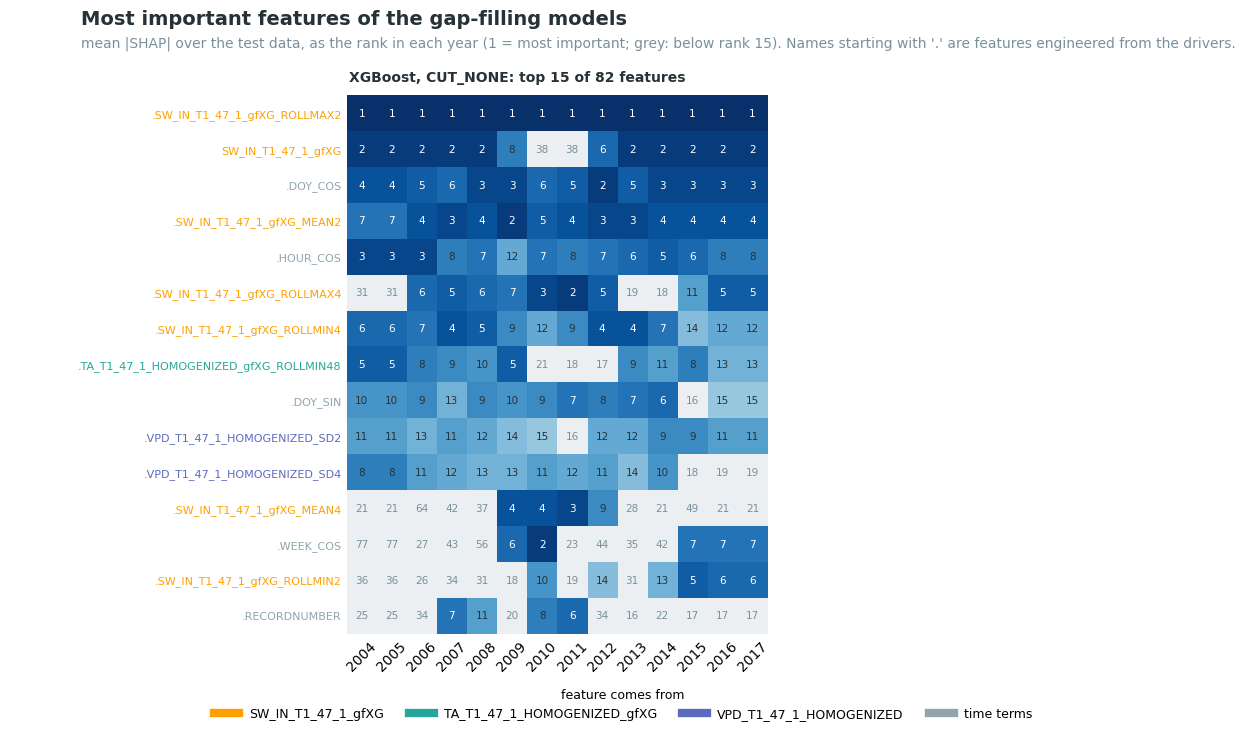

In [39]:
plot_feature_ranks_per_year(data)

## Step 10: result plots

### 📊 Plot: LE by quality class, heatmaps, XGBoost

The highest-quality records (QCF 0), the records the gap-filling used (QCF 0 and 1), the rejected
records, and the gap-filled result, on one colour scale.

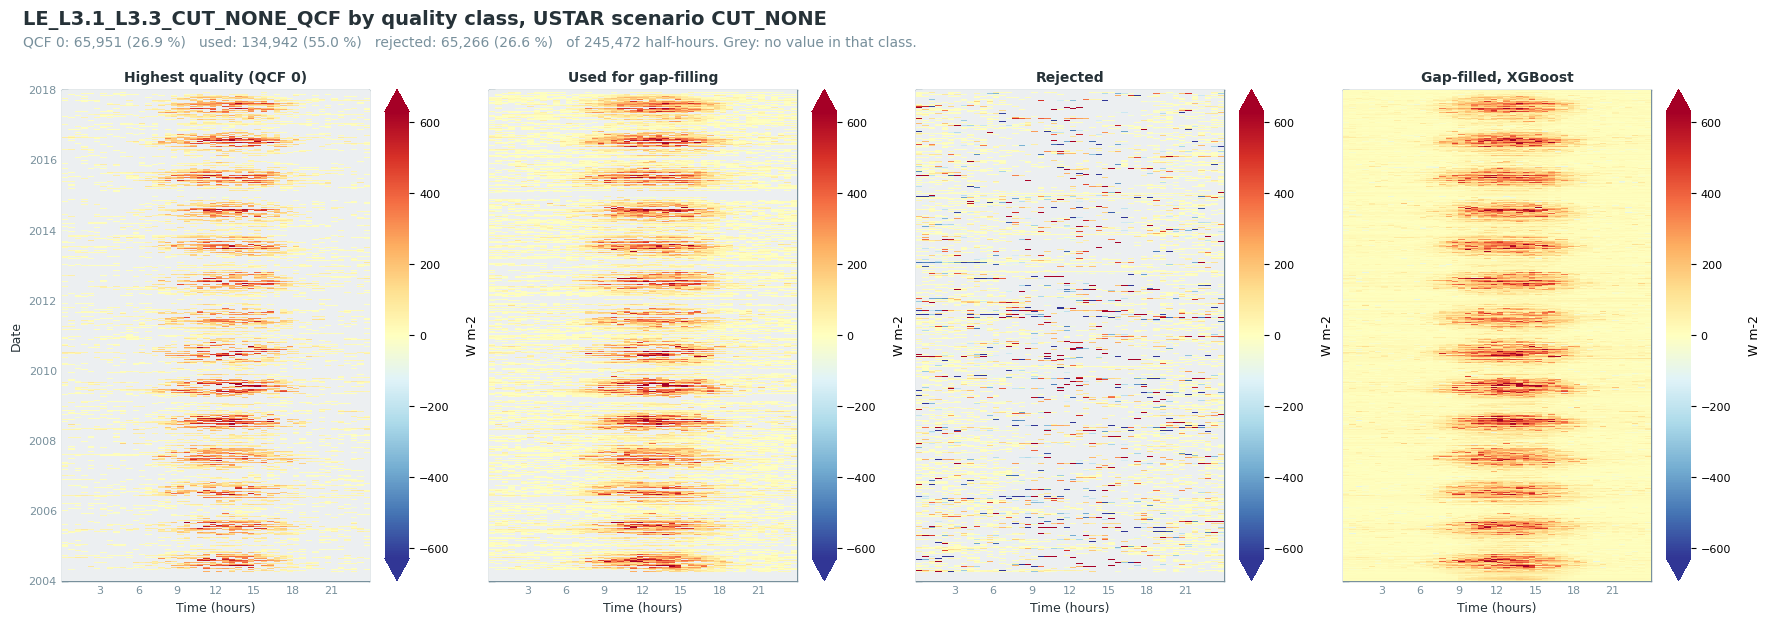

In [40]:
plot_quality_heatmaps(data, ustar_scenario=USTAR_SCENARIO, units=FLUX_UNITS, method='xgb')

### 📊 Plot: LE by quality class, day and night, XGBoost

Daytime and nighttime records by quality class, then the gap-filled result, with measured and
filled records shown apart.

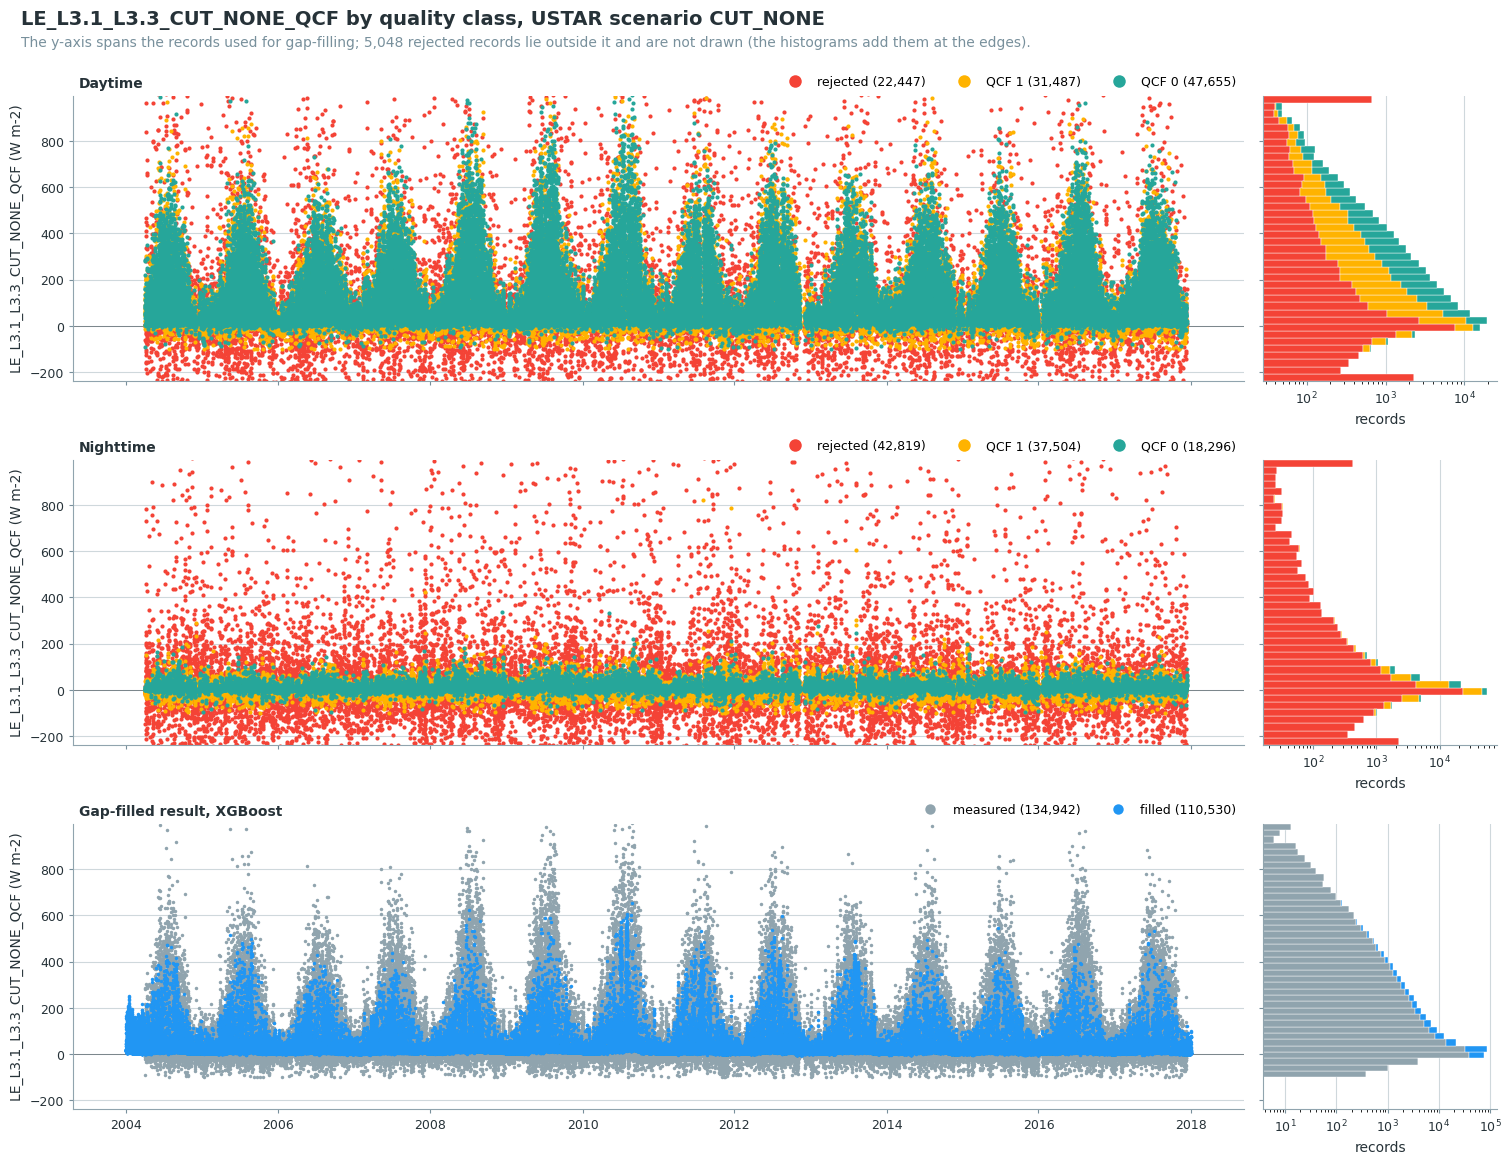

In [41]:
plot_quality_timeseries(data, ustar_scenario=USTAR_SCENARIO, units=FLUX_UNITS, method='xgb')

### 📊 Plot: measured and gap-filled LE

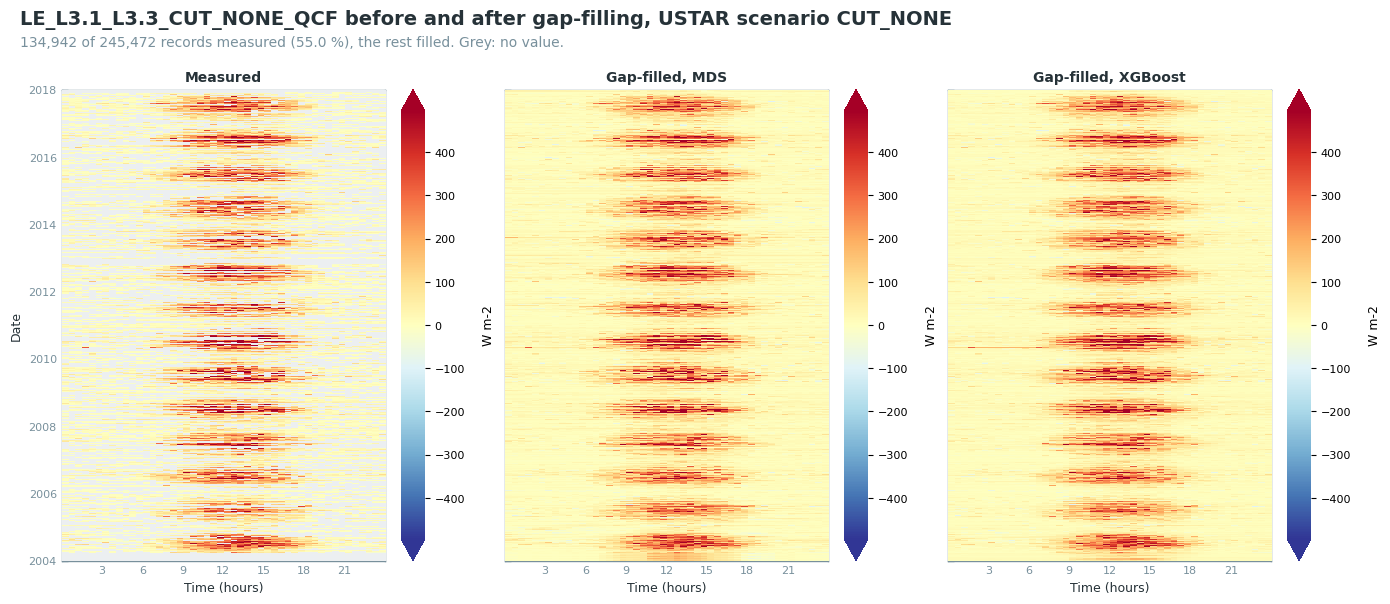

In [42]:
data.plot_gapfilled_heatmaps(ustar_scenario=USTAR_SCENARIO, units=FLUX_UNITS)

### 📊 Plot: cumulative LE

One line per gap-filling method, and the measured records alone (gaps counted as zero).

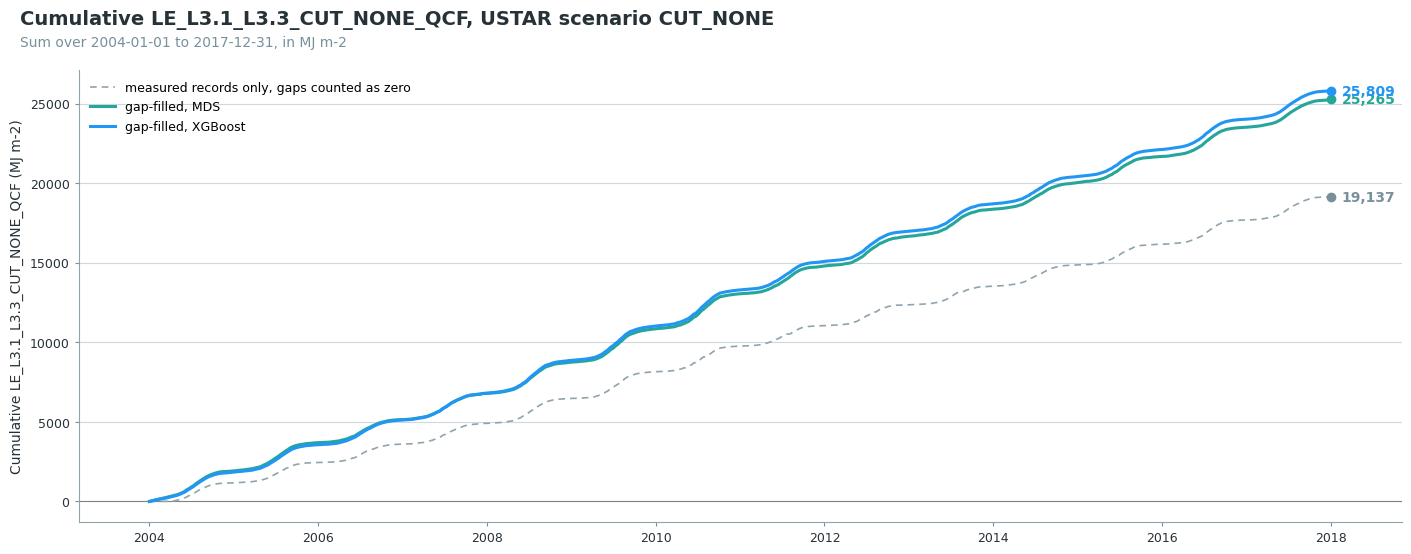

In [43]:
data.plot_cumulative_comparison(
    ustar_scenario=USTAR_SCENARIO,
    conv_factor=W_TO_MJ,
    units='MJ m-2',
)

### 📊 Plot: cumulative LE per year

One panel per gap-filling method, on the same y-axis. One line per year; the band is the mean ± 1 SD
of the full years. An incomplete last year is left out of the band.

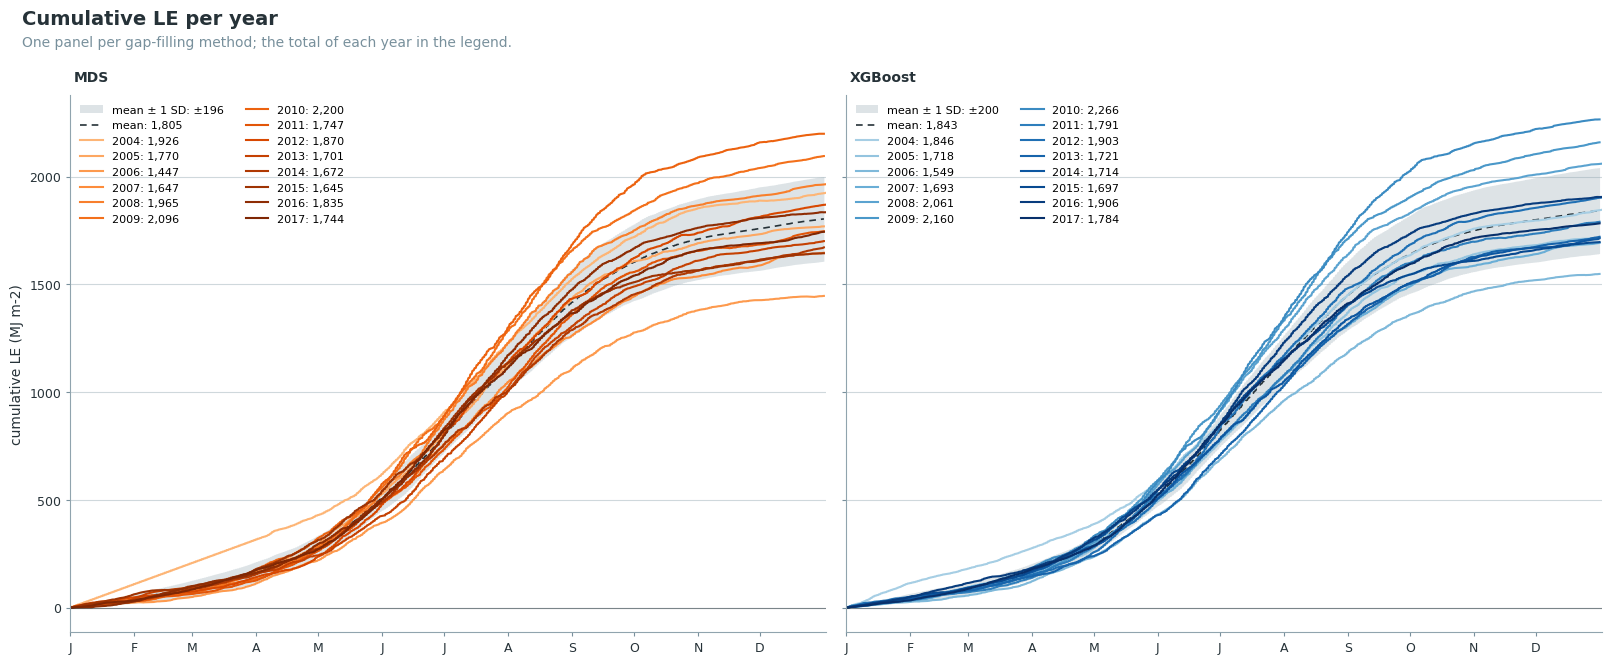

In [44]:
# One panel per gap-filling method, on a shared y-axis. Years run from light to dark, so the most
# recent year is the darkest line.
_gf = data.gapfilled_cols()
_names = {'mds': 'MDS', 'xgb': 'XGBoost', 'rf': 'random forest'}
_months = [1, 32, 60, 91, 121, 152, 182, 213, 244, 274, 305, 335]
# A last year that ends before 31 December stays out of the mean and the band.
_end = data.fpc_df.index[-1]
_partial = [_end.year] if (_end.month, _end.day) != (12, 31) else None
fig, axes = plt.subplots(1, len(_gf), figsize=(8 * len(_gf), 6.6), sharex=True, sharey=True,
                         layout='constrained', squeeze=False)
for _ax, (_method, _cols) in zip(axes[0], _gf.items()):
    _cum = doy_cumulatives_per_year(data.fpc_df[_cols[USTAR_SCENARIO]] * W_TO_MJ)
    _cum = _cum.loc[:, _cum.notna().any()]
    _years = list(_cum.columns)
    _shades = plt.get_cmap(cp.METHOD_CMAPS.get(_method, 'Greys'))(
        np.linspace(0.35, 1.0, len(_years)) if len(_years) > 1 else [0.85])
    if len(_years) > 1:
        _ref = doy_mean_cumulative(cumulatives_per_year_df=_cum,
                                   excl_years_from_reference=_partial)
        # Day 366 exists only in leap years, so the band stops before it.
        _ref = _ref.loc[_ref.index < 366]
        # The legend gives the mean and SD of the annual totals of the full years.
        _totals = [_cum[_y].dropna().iloc[-1] for _y in _years if _y not in (_partial or [])]
        _end_mean, _end_sd = np.mean(_totals), np.std(_totals, ddof=1)
        _ax.fill_between(_ref.index, _ref['MEAN-SD'], _ref['MEAN+SD'], color=cp.KEPT,
                         alpha=0.3, linewidth=0, label=f'mean ± 1 SD: ±{_end_sd:,.0f}')
        _ax.plot(_ref.index, _ref['MEAN_DOY_TIME'], color=cp.INK, linewidth=1.2,
                 linestyle=(0, (4, 3)), label=f'mean: {_end_mean:,.0f}')
    for _shade, _year in zip(_shades, _years):
        _valid = _cum[_year].dropna()
        _ax.plot(_cum.index, _cum[_year], color=_shade, linewidth=1.5,
                 label=f"{_year}: {_valid.iloc[-1]:,.0f}")
    _ax.axhline(0, color=cp.INK, linewidth=0.8, alpha=0.5)
    cp.style_axes(_ax)
    cp.panel_label(_ax, _names.get(_method, _method))
    _ax.set_xticks(_months, ['J', 'F', 'M', 'A', 'M', 'J', 'J', 'A', 'S', 'O', 'N', 'D'])
    _ax.set_xlim(1, 367)
    _ax.legend(frameon=False, fontsize=8, ncol=1 if len(_years) < 8 else 2)
axes[0][0].set_ylabel('cumulative LE (MJ m-2)')
_subtitle = "One panel per gap-filling method; the total of each year in the legend."
if _partial:
    _subtitle += f" {_end.year} ends on {_end:%d %B} and is left out of the mean and the band."
cp.figure_title(fig, 'Cumulative LE per year', _subtitle)
plt.show()

### Gap-filling methods compared

The difference between the sums of MDS and XGBoost comes from the filled gaps alone; the table
splits it by day and night and by gap length ([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#method-comparison)).

**Skipped** when `RUN_MDS = False`.

#### 📋 Table: MDS and XGBoost, sums and their difference

In [45]:
if RUN_MDS:
    report_gapfilling_comparison(data, methods=('mds', 'xgb'), gain=W_TO_MJ, units='MJ m-2');

Gap-filling methods compared: MDS and XGBoost
              sum       sum                    from         from   gaps   gaps    gaps   gaps
USTAR         MDS   XGBoost   difference   day gaps   night gaps      1   2-12   13-48    >48
─────────────────────────────────────────────────────────────────────────────────────────────
CUT_NONE   25,265    25,809          544        450           95     34    234     244     32
Sums (MJ m-2). difference = XGBoost - MDS over the filled gaps, split into daytime and nighttime 
gaps and by gap length in records.
CUT_NONE, same 33,755 held-out records: MDS R² 0.69 RMSE 68.37, XGBoost R² 0.75 RMSE 60.41
Held-out records are random single half-hours, so these scores describe short gaps; the sums depend 
more on the long ones.

#### 📊 Plot: where MDS and XGBoost differ

The filled values of both methods at the same gaps, their mean difference by month and hour, the
contribution of each month to the difference of the sums, and the cumulative difference.

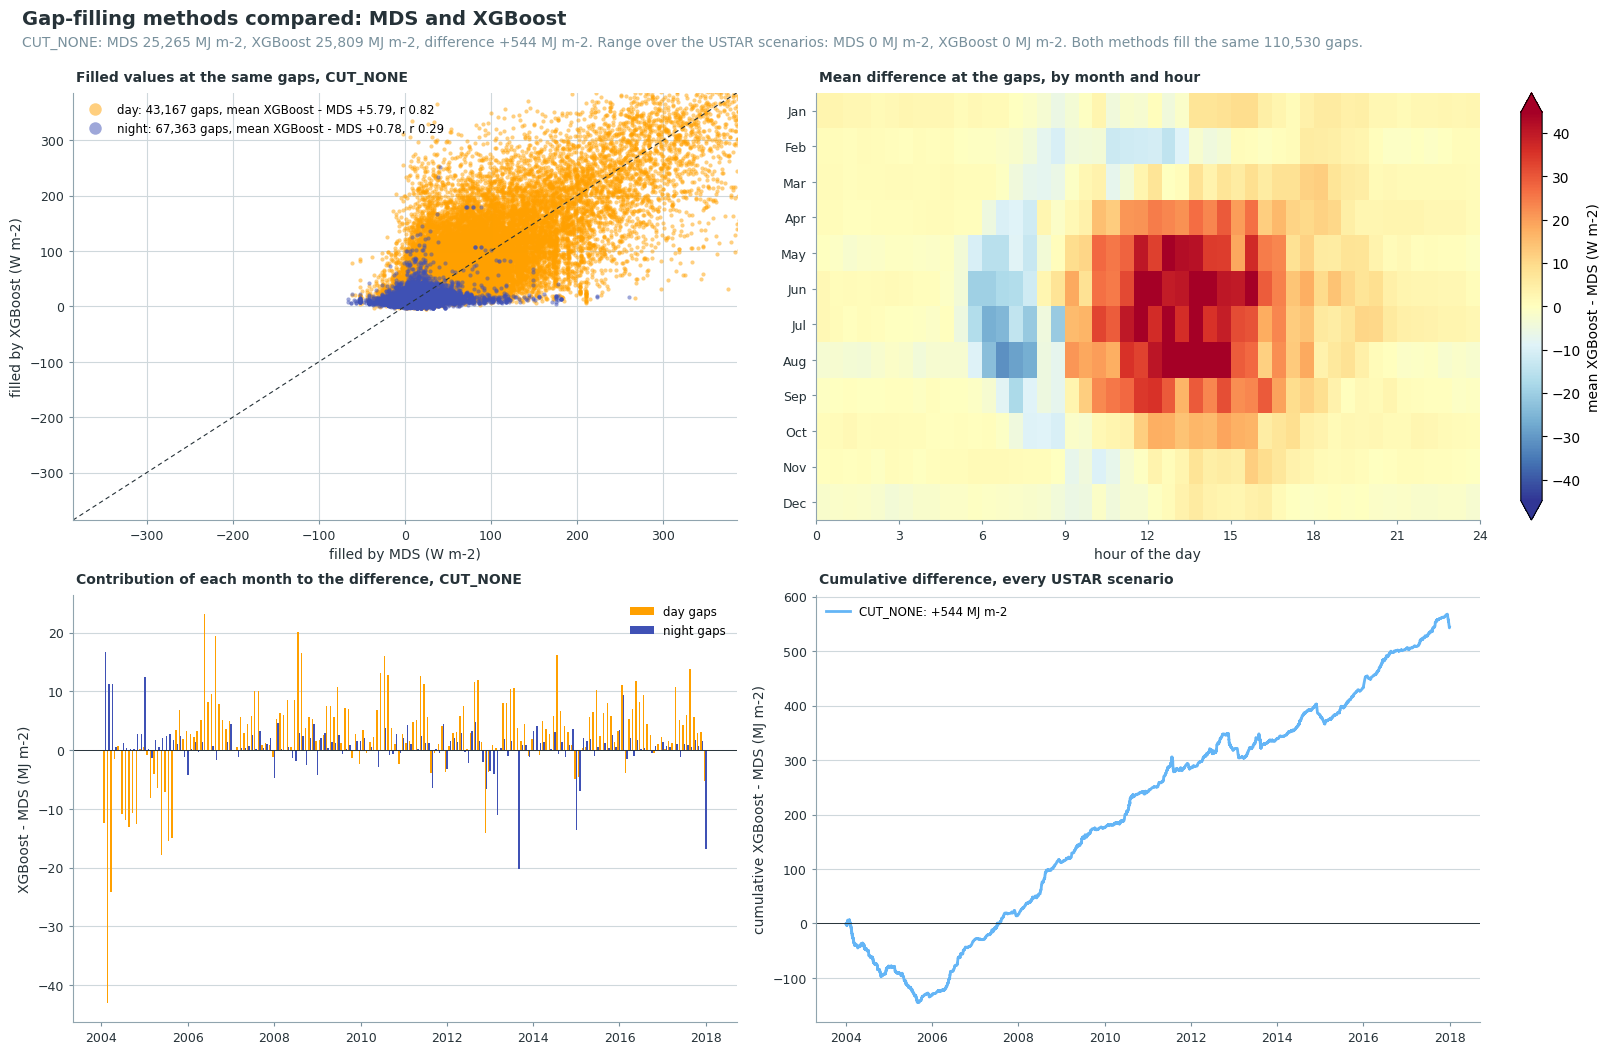

In [46]:
if RUN_MDS:
    plot_gapfilling_comparison(data, ustar_scenario=USTAR_SCENARIO, methods=('mds', 'xgb'),
                               gain=W_TO_MJ, units='MJ m-2', flux_units=FLUX_UNITS);

## Step 11: evapotranspiration

ET is LE divided by the latent heat of vaporization, which depends on air temperature
(`et_from_le` with `TA_F`, after the R package bigleaf). The ET column of each gap-filling method
holds mm per half-hour and sums directly to totals. The input column `ET` is the EddyPro rate of
the measured records only.

### 📋 Table: ET columns

In [47]:
_ta = data.full_df[TA_F].reindex(data.fpc_df.index)
assert _ta.notna().all(), f"{TA_F} has gaps"
ET_COLS = {}  # {method: ET column}
_et = {}
for _method, _cols in data.gapfilled_cols().items():
    _le = data.fpc_df[_cols[USTAR_SCENARIO]]
    assert _le.name.startswith(FLUXCOL), _le.name
    _name = 'ET' + _le.name[len(FLUXCOL):]
    _et[_name] = et_from_le(le=_le, ta=_ta) * HOURS_PER_RECORD  # mm h-1 -> mm per half-hour
    ET_COLS[_method] = _name
ET_EXPORT = pd.DataFrame(_et)
assert ET_EXPORT.notna().all().all(), "a gap-filled record has no ET"

_names = {'mds': 'MDS', 'xgb': 'XGBoost', 'rf': 'random forest'}
display(pd.DataFrame({
    'from LE column': [data.gapfilled_cols()[_k][USTAR_SCENARIO] for _k in ET_COLS],
    'method': [_names.get(_k, _k) for _k in ET_COLS],
    'units': 'mm per half-hour',
    'records': [int(ET_EXPORT[_c].count()) for _c in ET_COLS.values()],
    'mean (mm d-1)': [round(float(ET_EXPORT[_c].mean()) * 48, 2) for _c in ET_COLS.values()],
}, index=pd.Index(list(ET_COLS.values()), name='ET column')))

,from LE column,method,units,records,mean (mm d-1)
ET column,,,,,
ET_L3.1_L3.3_CUT_NONE_QCF_gfMDS,LE_L3.1_L3.3_CUT_NONE_QCF_gfMDS,MDS,mm per half-hour,245472,2.00
ET_L3.1_L3.3_CUT_NONE_QCF_gfXG,LE_L3.1_L3.3_CUT_NONE_QCF_gfXG,XGBoost,mm per half-hour,245472,2.05


### 📋 Table: annual sums of ET

Annual sums in mm for each gap-filling method, and their difference. An incomplete last year is a
partial sum.

In [48]:
ANNUAL_ET = ET_EXPORT.groupby(ET_EXPORT.index.year).sum()
ANNUAL_ET.columns = [_names.get(_k, _k) for _k in ET_COLS]
ANNUAL_ET.index.name = 'year'
if {'XGBoost', 'MDS'} <= set(ANNUAL_ET.columns):
    ANNUAL_ET['XGBoost - MDS'] = ANNUAL_ET['XGBoost'] - ANNUAL_ET['MDS']
print("Annual sums of ET (mm)")
display(ANNUAL_ET.round(1))

Annual sums of ET (mm)


,MDS,XGBoost,XGBoost - MDS
year,,,
2004,780.0,748.1,-31.9
2005,717.8,696.9,-20.9
2006,587.5,628.7,41.2
2007,668.1,686.7,18.6
2008,797.4,835.8,38.4
2009,851.0,876.8,25.7
2010,892.4,919.3,27.0
2011,709.4,727.1,17.7
2012,759.0,772.4,13.4


### 📊 Plot: annual sums of ET

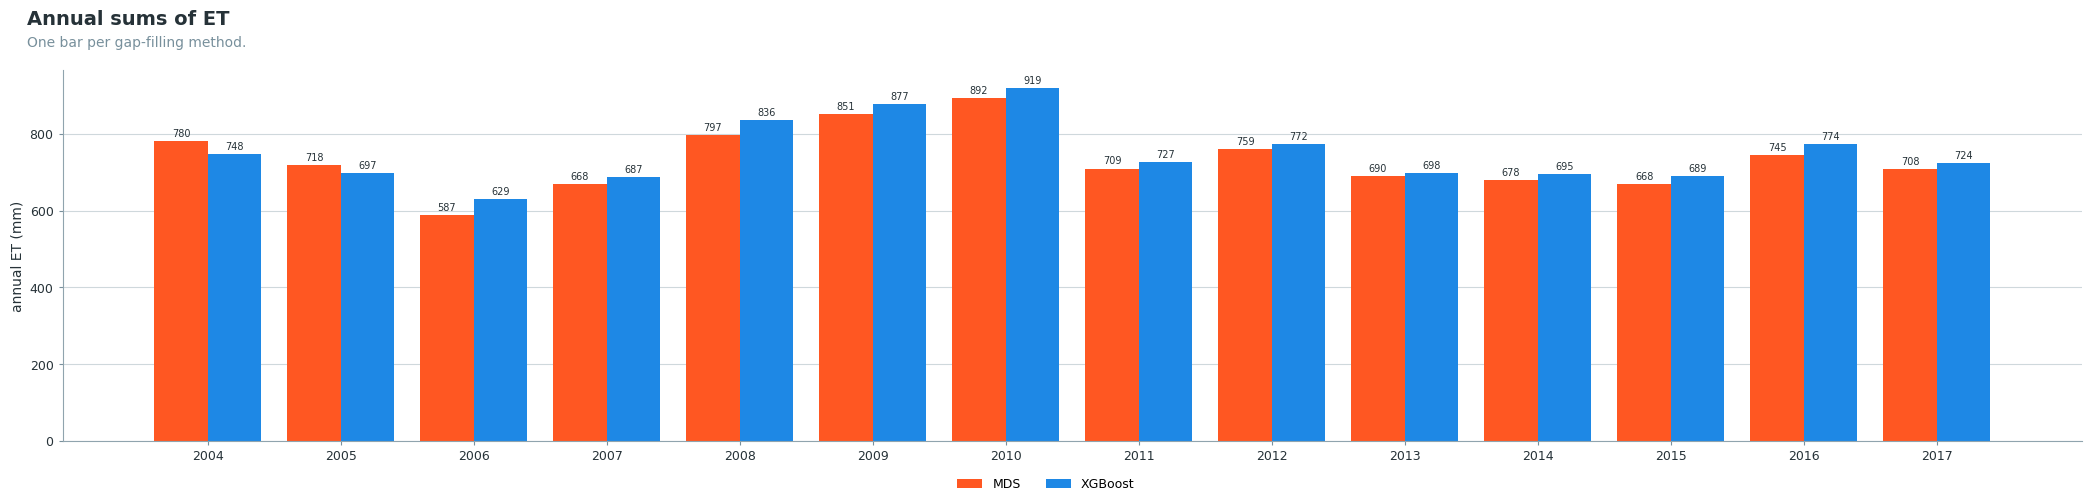

In [49]:
_colors = {_names.get(_k, _k): _v[1] for _k, _v in cp.METHOD_COLORS.items()}  # hue of each method
_methods = [_names.get(_k, _k) for _k in ET_COLS]
_years = ANNUAL_ET.index
_width = 0.8 / len(_methods)
_end = ET_EXPORT.index[-1]
fig, ax = plt.subplots(figsize=(max(8, 1.2 * len(_years) + 4), 5), layout='constrained')
for _i, _method in enumerate(_methods):
    _x = np.arange(len(_years)) + (_i - (len(_methods) - 1) / 2) * _width
    ax.bar(_x, ANNUAL_ET[_method], _width, color=_colors.get(_method, cp.KEPT), label=_method)
    for _xi, _v in zip(_x, ANNUAL_ET[_method]):
        ax.annotate(f'{_v:.0f}', (_xi, _v), ha='center', va='bottom', fontsize=7, color=cp.INK,
                    xytext=(0, 2), textcoords='offset points')
ax.set_xticks(np.arange(len(_years)), _years)
ax.set_ylabel('annual ET (mm)')
cp.style_axes(ax)
fig.legend(*ax.get_legend_handles_labels(), loc='outside lower center', frameon=False,
           ncol=len(_methods), fontsize=9)
cp.figure_title(fig, 'Annual sums of ET',
                "One bar per gap-filling method."
                + (f" {_end.year} ends on {_end:%d %B}." if (_end.month, _end.day) != (12, 31)
                   else ""))
plt.show()

## 💾 Step 12: export

The output file holds only what this notebook adds: every column the chain created and the ET
columns of Step 11. The input columns stay unchanged in the input file; the merge into the fullset
joins the outputs of the flux notebooks with it on the timestamp.

In [50]:
# Only the new columns: the input columns are in the input file and are added back in the merge.
_all = data.merged_df().join(ET_EXPORT)
out_df = _all[[c for c in _all.columns if c not in df.columns]]
assert out_df.index.equals(df.index), "the output timestamps differ from the input"
assert set(ET_EXPORT.columns) <= set(out_df.columns), "ET columns missing from the output"
print(f"ET columns in the output: {list(ET_EXPORT.columns)}")
print(f"{out_df.shape[0]:,} records x {out_df.shape[1]} columns (input columns left out: "
      f"{_all.shape[1] - out_df.shape[1]})")
filepath = dv.save_parquet(data=out_df, filename=OUTNAME, outpath=OUTPATH)

> New variables from the flux post-processing chain: 40 (L2: 12, L3.1: 7, L3.2: 10, L3.3: 7, L4.1:
4)

> No variables in the input data were overwritten, only new variables added.

ET columns in the output: ['ET_L3.1_L3.3_CUT_NONE_QCF_gfMDS', 'ET_L3.1_L3.3_CUT_NONE_QCF_gfXG']
245,472 records x 45 columns (input columns left out: 348)


> Saved file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\30_FLUX_POST-PROC
ESSING_CHAIN\IRGA75\25_FPPC_IRGA75_LE_2004-2017.parquet (1.068 seconds).

***

# End of notebook.

In [51]:
NOTEBOOK_END = datetime.now()
_h, _rem = divmod(int((NOTEBOOK_END - NOTEBOOK_START).total_seconds()), 3600)
_m, _s = divmod(_rem, 60)

print(f"Started:  {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Finished: {NOTEBOOK_END.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Runtime:  {_h:02d}:{_m:02d}:{_s:02d} (hh:mm:ss)")

Started:  2026-10-30 18:22:19
Finished: 2026-10-30 18:46:41
Runtime:  00:24:22 (hh:mm:ss)
